Developing Retention Models for Credit Card Customers

In [1]:
# data manipulation
import pandas as pd
import numpy as np

# data viz
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

# apply some cool styling
plt.style.use("ggplot")
rcParams['figure.figsize'] = (12, 6)

# use sklearn to import a dataset
from sklearn.datasets import load_wine

#import frequently used libraries- hocadan aldıklarım 
import math
from scipy.stats import norm
from scipy.stats import lognorm
from scipy.stats import chi2
from scipy.stats import t
from scipy.stats import f

import scipy.stats as sc 
import statsmodels.graphics.gofplots as sm 
#pip install bbplot 

TRAINING DATA

In [2]:
df=pd.read_csv("imputed_train (1).csv")

print(df) #shows the content of the file or, if the file is large, the first and last 5 rows of the file

print(df.columns) #shows the names of the columns, which you will use to refer 

       CAT1  CAT2  CAT3  CAT4  CAT5  CAT6  CAT7  CAT8  CAT9  CAT10  ...  \
0         7    12     7     7    11     3    55    10     7      3  ...   
1         2     4     3     4    33     1    49    10     7      2  ...   
2         7     8     4     1    67     3    53    10     0      4  ...   
3         4     8     7     3    52     1    49    10     0      4  ...   
4         2     8     4     1    40     3    54     7     0      4  ...   
...     ...   ...   ...   ...   ...   ...   ...   ...   ...    ...  ...   
49995     3     3     7     2     7     1    55    10     0      2  ...   
49996     2     8     7     3    78     2    55    10     7      4  ...   
49997     4     6     9     1     7     2     1     9     0      5  ...   
49998     5     1     3     4    40     1    36    10     1      2  ...   
49999     5     1     4     6    73     1    49     2     0      2  ...   

       NUM19  NUM20  NUM21  NUM22  NUM23  NUM24  NUM25     NUM26     NUM27  \
0        1.0    2.0  

In [3]:
df.head()


,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27,TARGET
0,7,12,7,7,11,3,55,10,7,3,...,1.0,2.0,1.0,1.0,0.6,0.0,2.0,0.039196,0.095146,0
1,2,4,3,4,33,1,49,10,7,2,...,11.0,6.0,8.0,13.0,0.6,1.0,0.0,0.031361,0.095672,0
2,7,8,4,1,67,3,53,10,0,4,...,4.0,6.0,6.0,4.0,0.6,7.0,6.0,0.026348,0.089032,0
3,4,8,7,3,52,1,49,10,0,4,...,7.0,7.0,5.0,10.0,0.6,5.0,5.0,0.031773,0.087314,0
4,2,8,4,1,40,3,54,7,0,4,...,5.0,6.0,4.0,8.0,0.6,0.0,0.0,0.023150,0.093865,0


In [4]:
df.tail()

,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27,TARGET
49995,3,3,7,2,7,1,55,10,0,2,...,7.0,9.0,7.0,8.0,0.2,0.0,11.0,0.038615,0.096702,0
49996,2,8,7,3,78,2,55,10,7,4,...,3.0,8.0,5.0,8.0,0.2,0.0,6.0,0.036619,0.095709,0
49997,4,6,9,1,7,2,1,9,0,5,...,3.0,7.0,4.0,5.0,0.2,8.0,5.0,0.046931,0.097862,0
49998,5,1,3,4,40,1,36,10,1,2,...,11.0,11.0,12.0,12.0,0.2,5.0,12.0,0.022959,0.089737,0
49999,5,1,4,6,73,1,49,2,0,2,...,9.0,9.0,9.0,10.0,0.2,10.0,7.0,0.031750,0.096268,0


In [5]:
df.shape


(50000, 48)

In [6]:
df.describe()

,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27,TARGET
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,4.331520,6.377440,4.120960,3.587520,36.97714,1.710360,39.894740,7.721560,1.635540,2.975540,...,6.162120,5.661840,5.641640,7.670020,0.332555,3.17898,4.727060,0.033596,0.095560,0.092480
std,1.886151,4.810281,1.742914,2.078679,20.14747,0.790975,17.184244,3.284224,2.688281,1.140249,...,3.929487,3.374954,4.137473,4.014371,0.333326,3.44985,4.180731,0.008641,0.004767,0.289705
min,0.000000,0.000000,1.000000,0.000000,1.00000,1.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.018290,0.081922,0.000000
25%,3.000000,3.000000,4.000000,2.000000,21.00000,1.000000,29.000000,4.000000,0.000000,2.000000,...,3.000000,2.000000,2.000000,4.000000,0.060000,0.00000,0.000000,0.027657,0.094086,0.000000
50%,5.000000,4.000000,4.000000,3.000000,40.00000,2.000000,49.000000,10.000000,0.000000,2.000000,...,7.000000,7.000000,6.000000,8.000000,0.200000,2.00000,4.000000,0.032972,0.095973,0.000000
75%,6.000000,10.000000,4.000000,6.000000,52.00000,2.000000,55.000000,10.000000,2.000000,4.000000,...,9.000000,8.000000,9.000000,11.000000,0.550000,6.00000,8.000000,0.037172,0.098078,0.000000
max,7.000000,16.000000,9.000000,7.000000,81.00000,3.000000,56.000000,10.000000,7.000000,5.000000,...,13.000000,11.000000,13.000000,13.000000,1.000000,12.00000,14.000000,0.120198,0.146049,1.000000


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 48 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CAT1    50000 non-null  int64  
 1   CAT2    50000 non-null  int64  
 2   CAT3    50000 non-null  int64  
 3   CAT4    50000 non-null  int64  
 4   CAT5    50000 non-null  int64  
 5   CAT6    50000 non-null  int64  
 6   CAT7    50000 non-null  int64  
 7   CAT8    50000 non-null  int64  
 8   CAT9    50000 non-null  int64  
 9   CAT10   50000 non-null  int64  
 10  CAT11   50000 non-null  int64  
 11  CAT12   50000 non-null  int64  
 12  CAT13   50000 non-null  int64  
 13  CAT14   50000 non-null  int64  
 14  CAT15   50000 non-null  int64  
 15  CAT16   50000 non-null  int64  
 16  CAT17   50000 non-null  int64  
 17  CAT18   50000 non-null  int64  
 18  CAT19   50000 non-null  int64  
 19  CAT20   50000 non-null  int64  
 20  NUM1    50000 non-null  float64
 21  NUM2    50000 non-null  float64
 22

In [8]:
df.columns = ['cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7','cat8', 'cat9', 'cat10','cat11', 'cat12', 'cat13', 'cat14', 'cat15', 'cat16','cat17', 'cat18', 'cat19','cat20', 'num1', 'num2', 'num3', 'num4', 'num5', 'num6','num7', 'num8', 'num9', 'num10',  'num11', 'num12', 'num13', 'num14', 'num15', 'num16', 'num17', 'num18', 'num19', 'num20','num21', 'num22','num23', 'num24', 'num25', 'num26','num27', 'target']
df.head()
df.tail()


,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,...,num19,num20,num21,num22,num23,num24,num25,num26,num27,target
49995,3,3,7,2,7,1,55,10,0,2,...,7.0,9.0,7.0,8.0,0.2,0.0,11.0,0.038615,0.096702,0
49996,2,8,7,3,78,2,55,10,7,4,...,3.0,8.0,5.0,8.0,0.2,0.0,6.0,0.036619,0.095709,0
49997,4,6,9,1,7,2,1,9,0,5,...,3.0,7.0,4.0,5.0,0.2,8.0,5.0,0.046931,0.097862,0
49998,5,1,3,4,40,1,36,10,1,2,...,11.0,11.0,12.0,12.0,0.2,5.0,12.0,0.022959,0.089737,0
49999,5,1,4,6,73,1,49,2,0,2,...,9.0,9.0,9.0,10.0,0.2,10.0,7.0,0.031750,0.096268,0


In [9]:
df['num1']= df['num1'].astype(float)
df['num2']= df['num2'].astype(float)
df['num3']= df['num3'].astype(float)
df['num4']= df['num4'].astype(float)
df['num5']= df['num5'].astype(float)
df['num6']= df['num6'].astype(float)
df['num7']= df['num7'].astype(float)
df['num8']= df['num8'].astype(float)
df['num9']= df['num9'].astype(float)
df['num10']= df['num10'].astype(float)
df['num11']= df['num11'].astype(float)
df['num12']= df['num12'].astype(float)
df['num13']= df['num13'].astype(float)
df['num14']= df['num14'].astype(float)
df['num15']= df['num15'].astype(float)
df['num16']= df['num16'].astype(float)
df['num17']= df['num17'].astype(float)
df['num18']= df['num6'].astype(float)
df['num19']= df['num19'].astype(float)
df['num20']= df['num20'].astype(float)
df['num21']= df['num21'].astype(float)
df['num22']= df['num22'].astype(float)
df['num23']= df['num23'].astype(float)
df['num24']= df['num24'].astype(float)
df['num25']= df['num25'].astype(float)
df['num26']= df['num26'].astype(float)
df['num27']= df['num27'].astype(float)

UNDERSTANDING VARIABLES

CATEGORICAL VARIABLES

In [10]:
#understanding of the variables
#categorical variables
#for the target variable
df.target.value_counts()

0    45376
1     4624
Name: target, dtype: int64

In [11]:
#to express as percentage by normalizing 
df.target.value_counts(normalize = True)

0    0.90752
1    0.09248
Name: target, dtype: float64

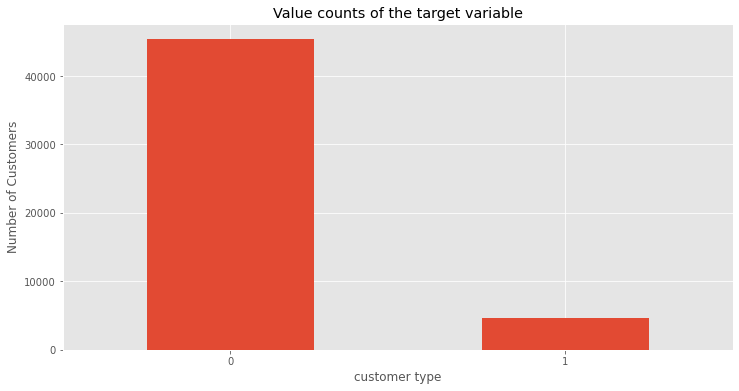

In [12]:
df.target.value_counts().plot(kind="bar")
plt.title("Value counts of the target variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

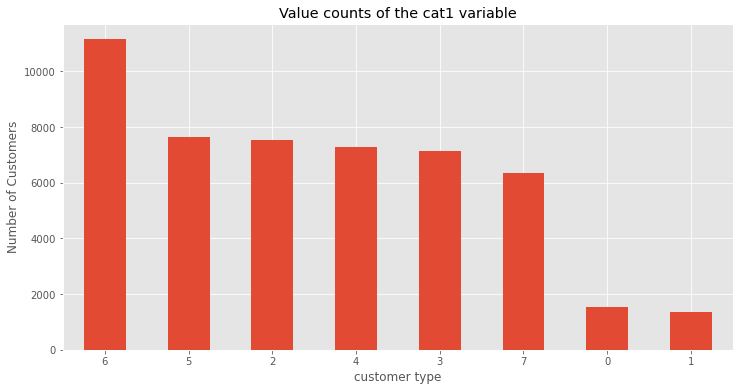

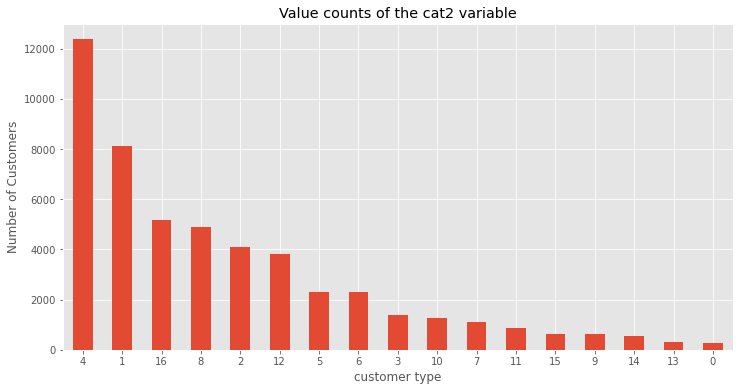

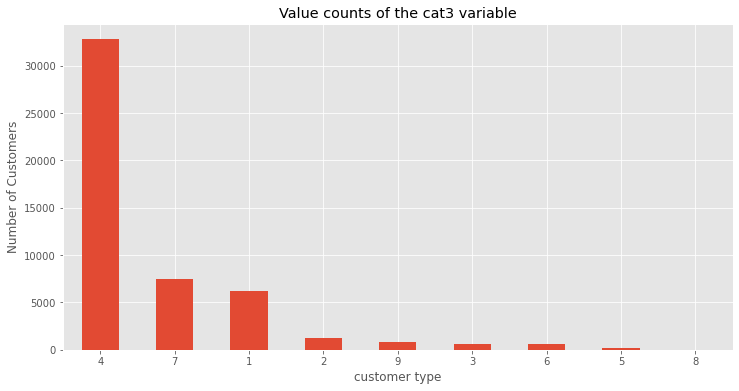

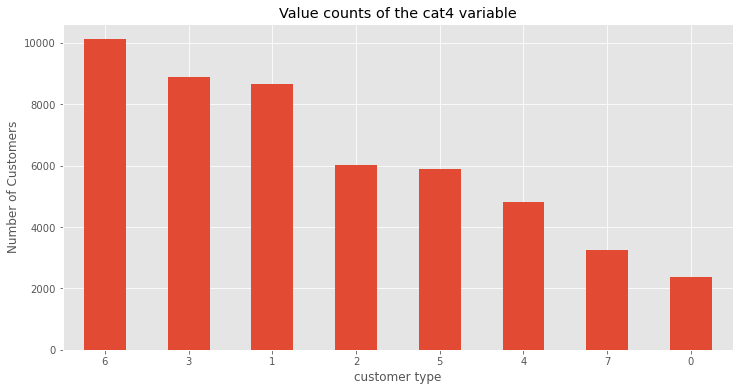

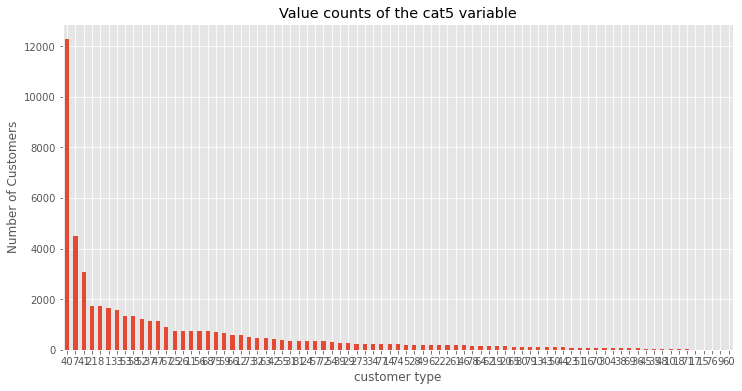

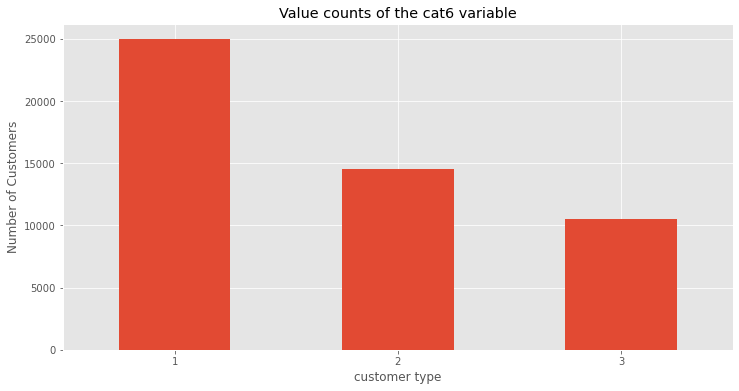

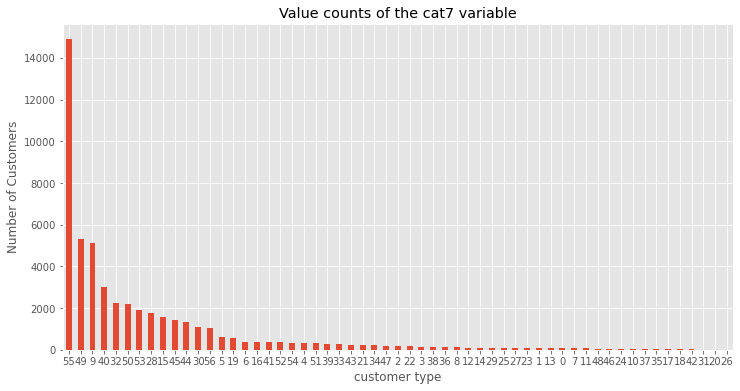

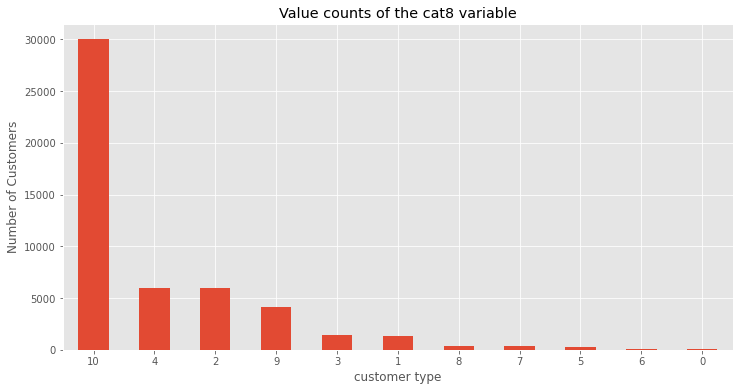

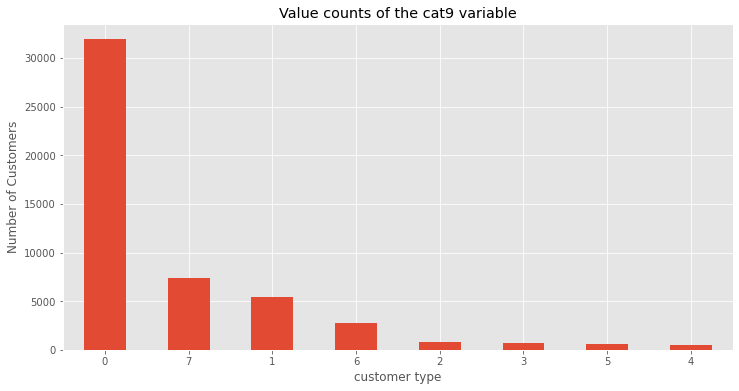

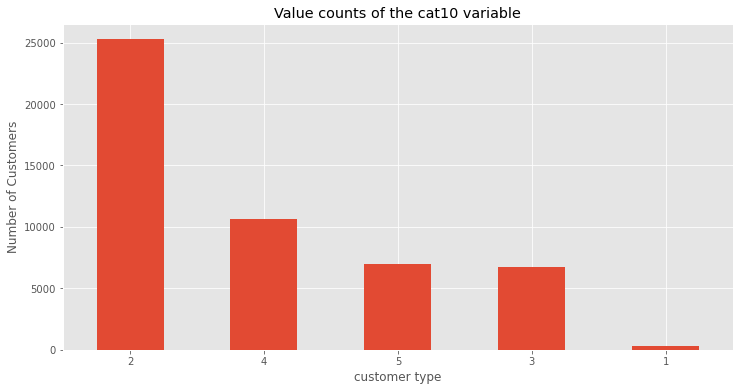

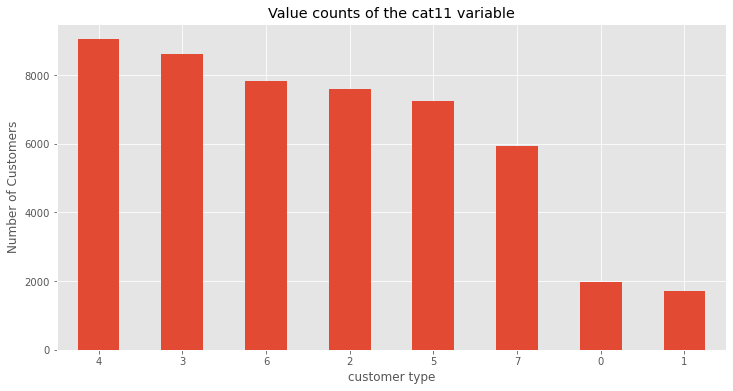

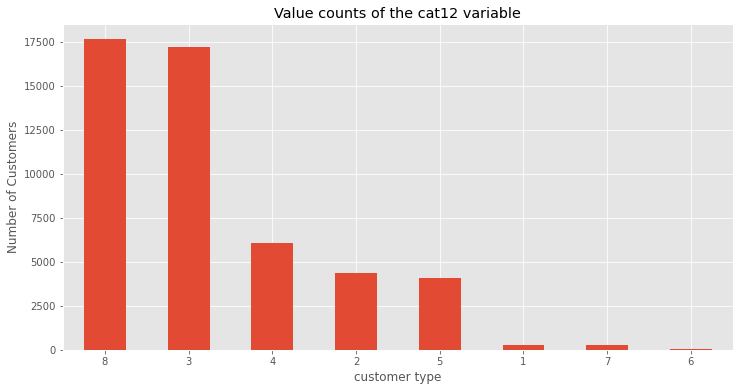

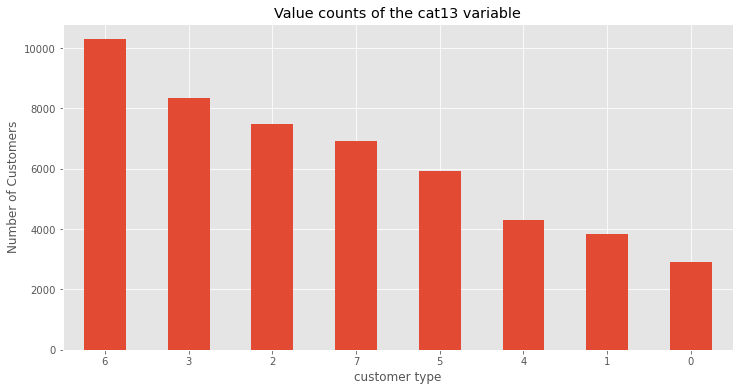

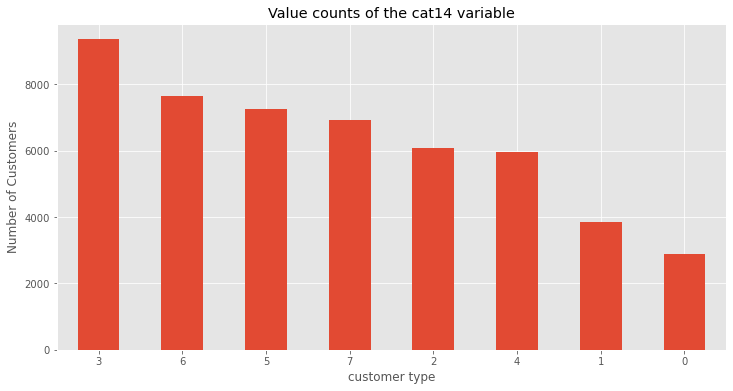

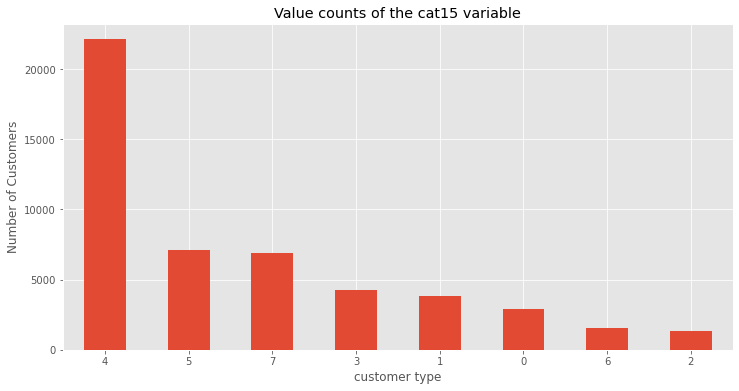

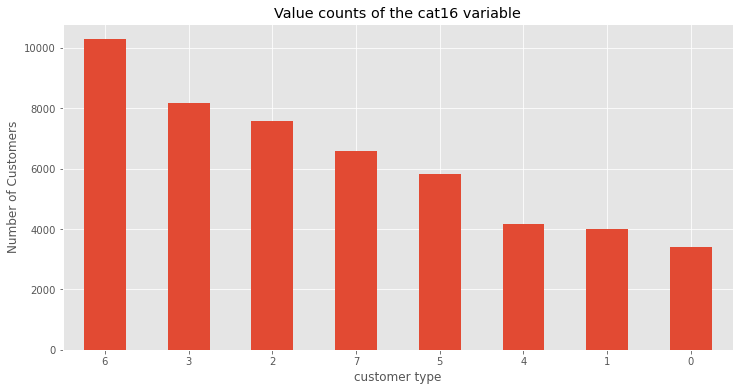

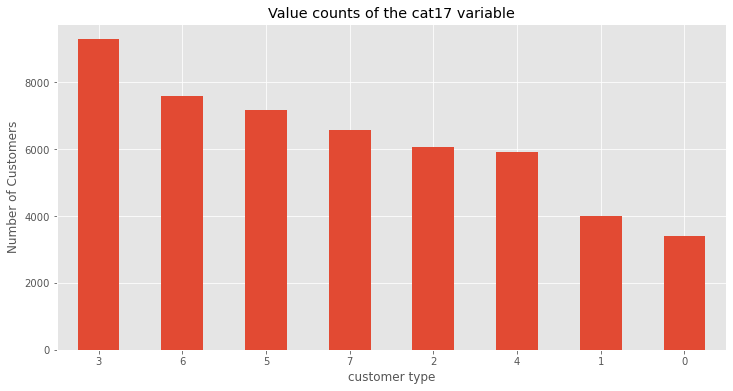

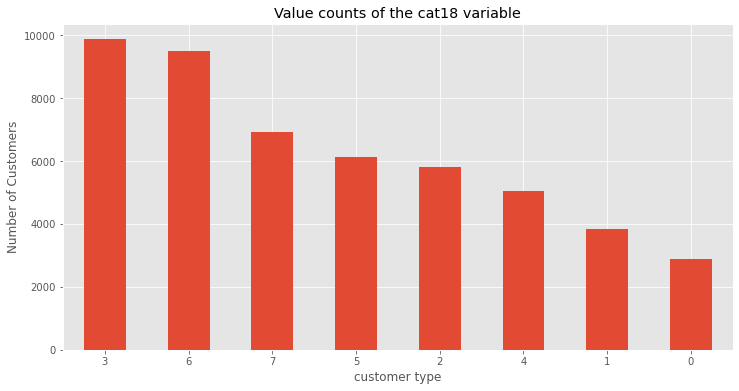

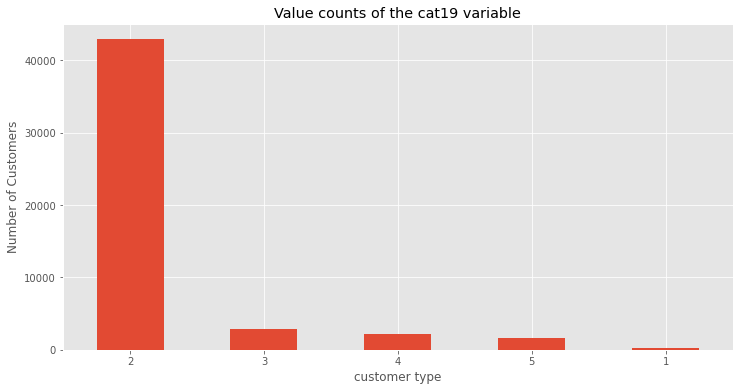

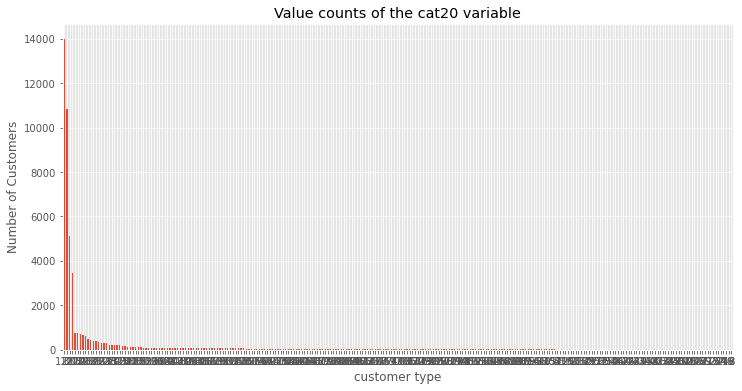

In [13]:
#for the remaining categorical variables starting with cat1 and ending with cat20
df.cat1.value_counts().plot(kind="bar")
plt.title("Value counts of the cat1 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat2.value_counts().plot(kind="bar")
plt.title("Value counts of the cat2 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat3.value_counts().plot(kind="bar")
plt.title("Value counts of the cat3 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat4.value_counts().plot(kind="bar")
plt.title("Value counts of the cat4 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat5.value_counts().plot(kind="bar")
plt.title("Value counts of the cat5 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat6.value_counts().plot(kind="bar")
plt.title("Value counts of the cat6 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat7.value_counts().plot(kind="bar")
plt.title("Value counts of the cat7 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat8.value_counts().plot(kind="bar")
plt.title("Value counts of the cat8 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat9.value_counts().plot(kind="bar")
plt.title("Value counts of the cat9 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat10.value_counts().plot(kind="bar")
plt.title("Value counts of the cat10 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat11.value_counts().plot(kind="bar")
plt.title("Value counts of the cat11 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat12.value_counts().plot(kind="bar")
plt.title("Value counts of the cat12 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()


df.cat13.value_counts().plot(kind="bar")
plt.title("Value counts of the cat13 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat14.value_counts().plot(kind="bar")
plt.title("Value counts of the cat14 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat15.value_counts().plot(kind="bar")
plt.title("Value counts of the cat15 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat16.value_counts().plot(kind="bar")
plt.title("Value counts of the cat16 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat17.value_counts().plot(kind="bar")
plt.title("Value counts of the cat17 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat18.value_counts().plot(kind="bar")
plt.title("Value counts of the cat18 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat19.value_counts().plot(kind="bar")
plt.title("Value counts of the cat19 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat20.value_counts().plot(kind="bar")
plt.title("Value counts of the cat20 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

HEAT MAP FOR CATEGORIC VARIABLES

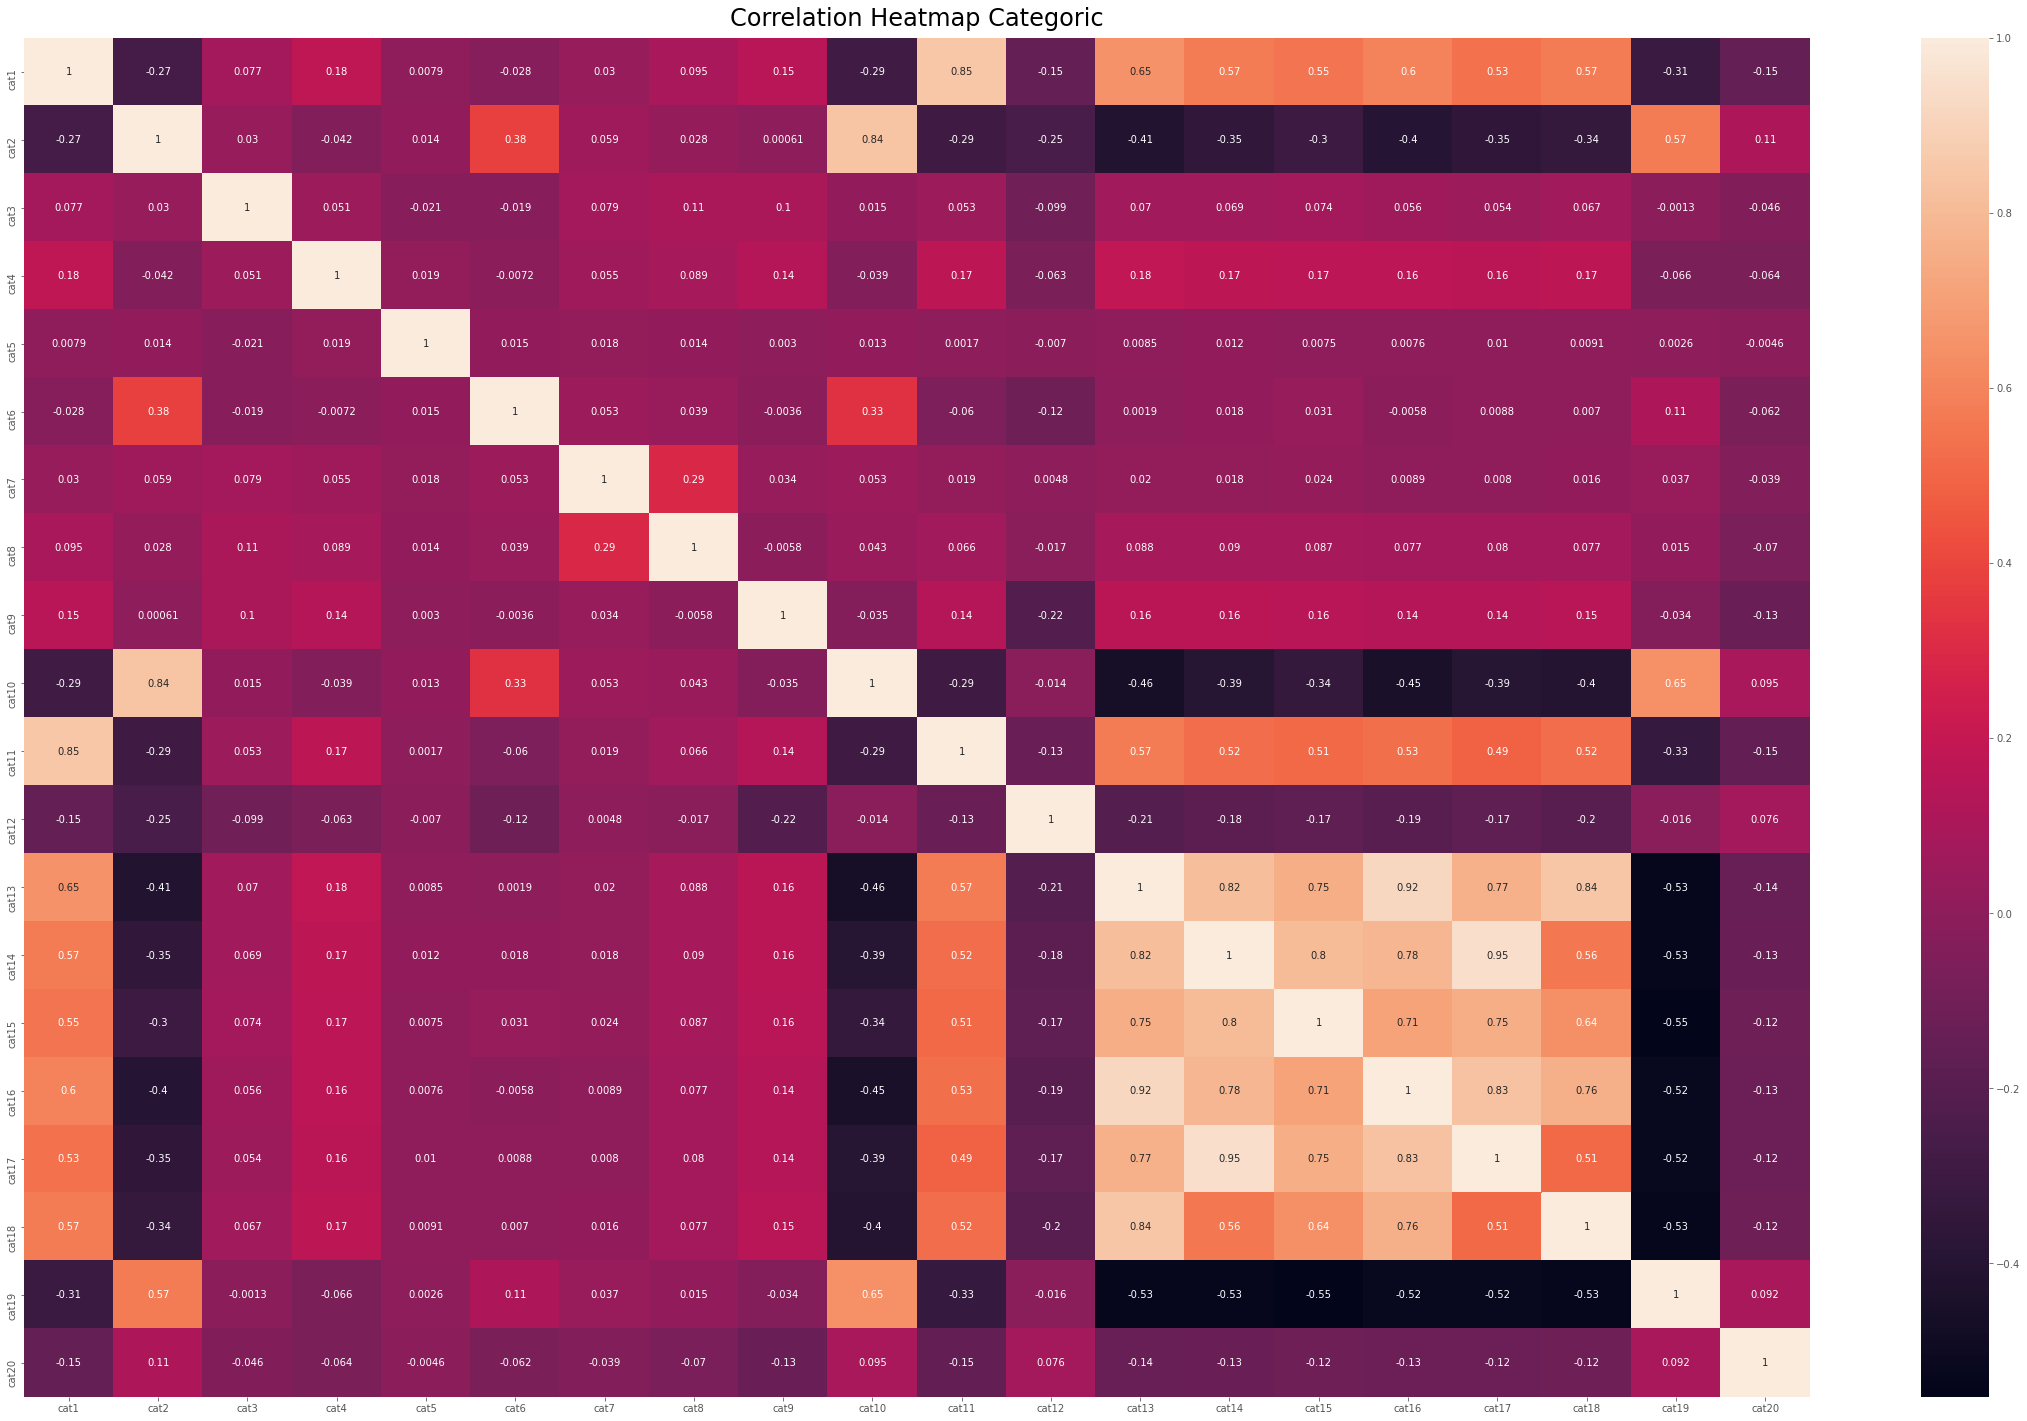

In [14]:
#heatmap for only categoric variables
data_cat = df.iloc[:,0:20]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data_cat.corr(method='spearman'), annot=True,yticklabels=data_cat.columns,xticklabels=data_cat.columns)
heatmap.set_title('Correlation Heatmap Categoric', fontdict={'fontsize':24}, pad=12);

BOX PLOT FOR CATEGORIC VARIABLES

Text(0.5, 1.0, 'CAT20')

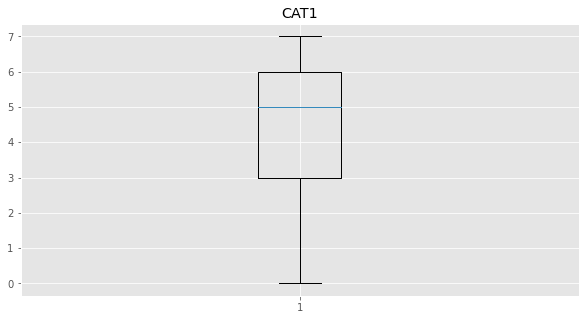

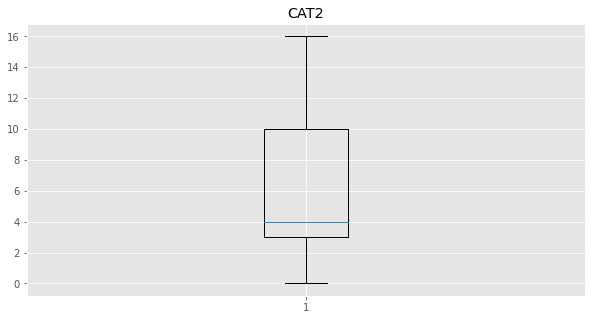

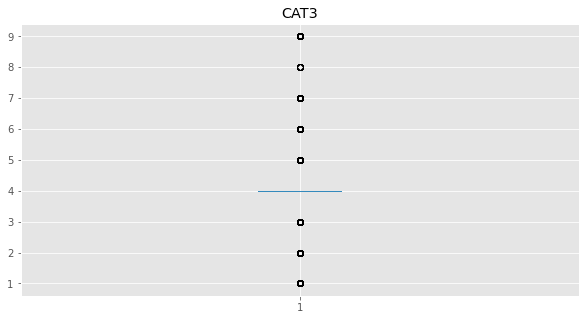

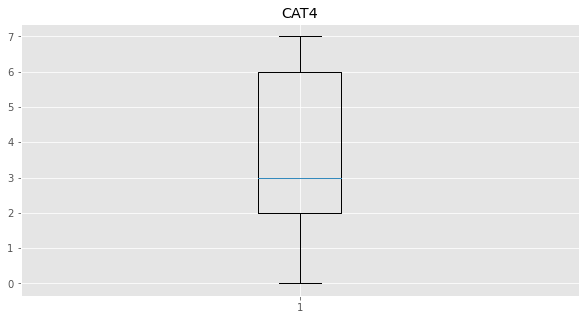

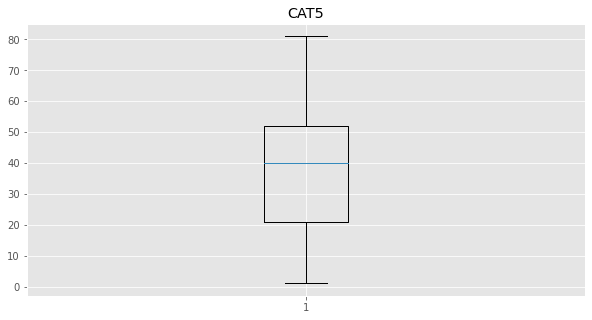

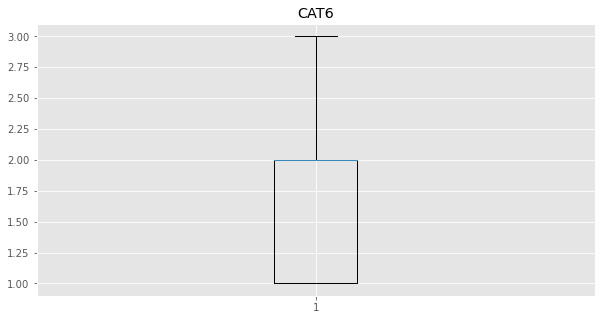

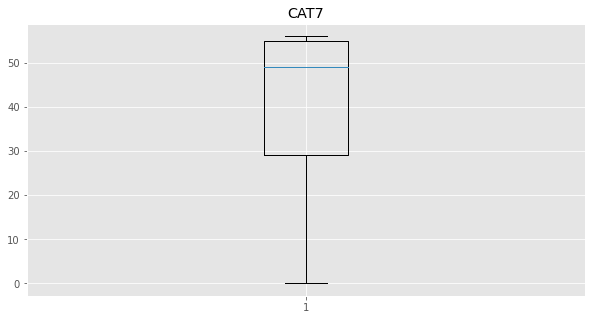

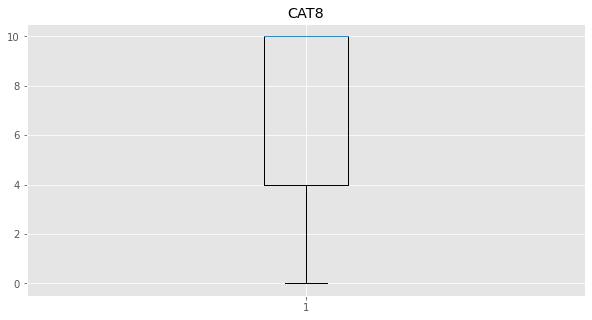

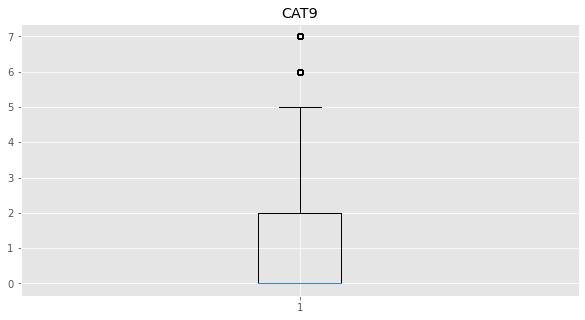

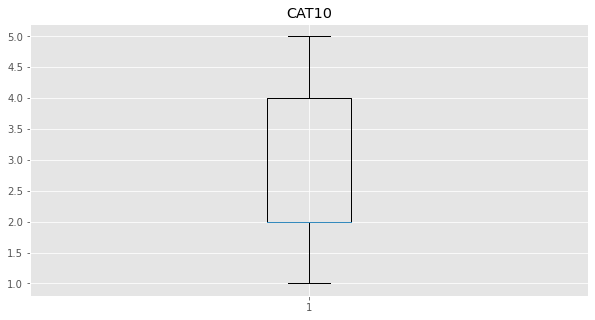

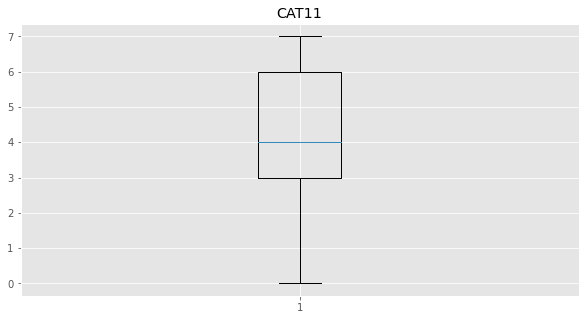

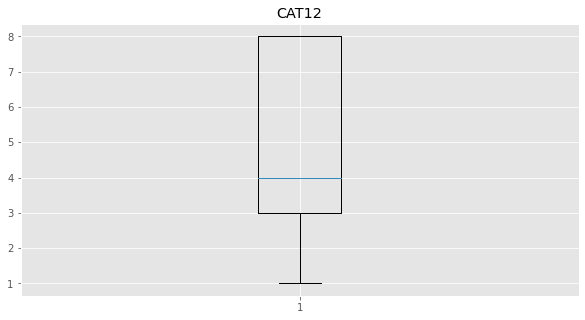

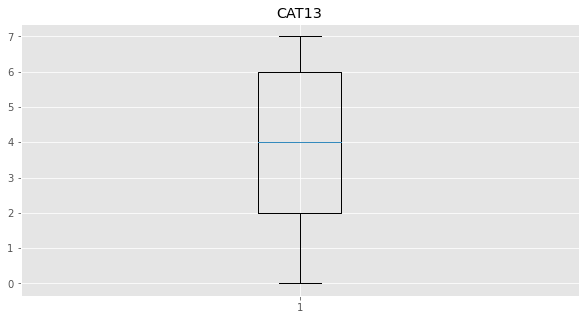

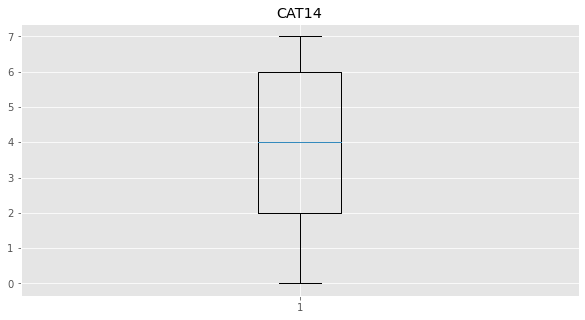

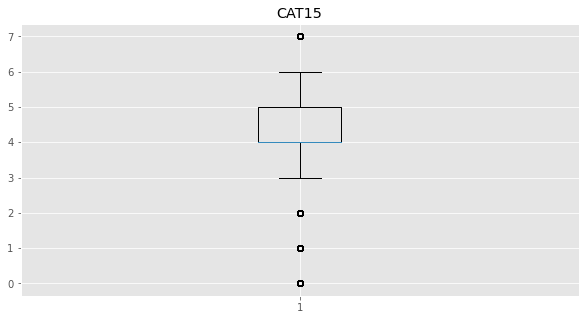

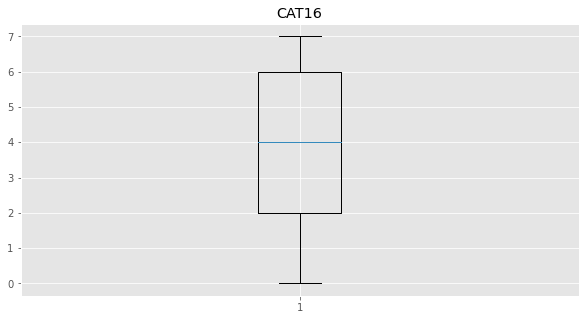

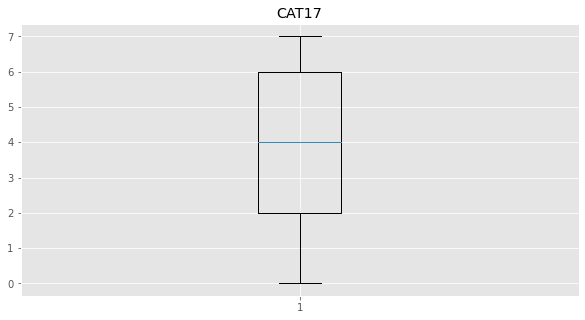

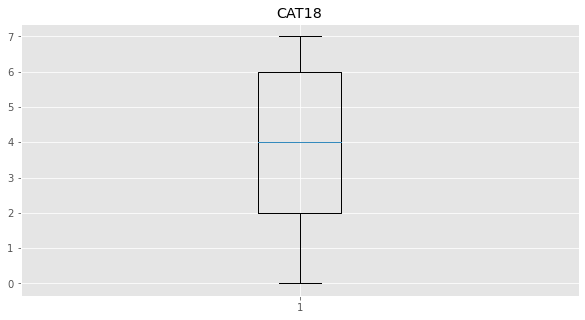

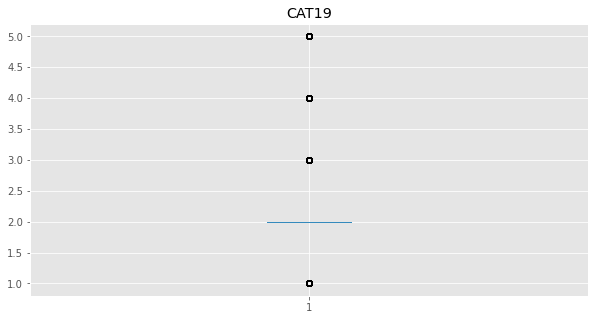

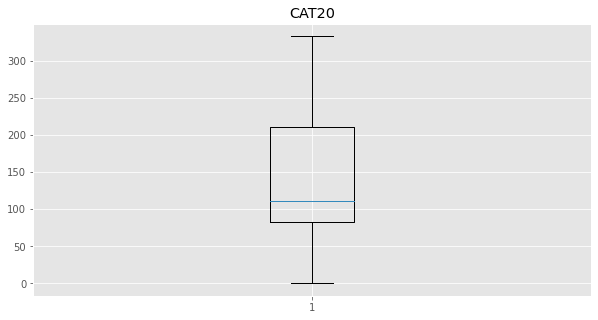

In [15]:
plt.figure(figsize=(10, 5))
plt.boxplot(df["cat1"])
plt.title('CAT1')
plt.figure(figsize=(10, 5))
plt.boxplot(df['cat2'])
plt.title('CAT2')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat3'])
plt.title('CAT3')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat4'])
plt.title('CAT4')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat5'])
plt.title('CAT5')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat6'])
plt.title('CAT6')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat7'])
plt.title('CAT7')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat8'])
plt.title('CAT8')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat9'])
plt.title('CAT9')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat10'])
plt.title('CAT10')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat11'])
plt.title('CAT11')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat12'])
plt.title('CAT12')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat13'])
plt.title('CAT13')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat14'])
plt.title('CAT14')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat15'])
plt.title('CAT15')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat16'])
plt.title('CAT16')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat17'])
plt.title('CAT17')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat18'])
plt.title('CAT18')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat19'])
plt.title('CAT19')


plt.figure(figsize=(10, 5))
plt.boxplot(df['cat20'])
plt.title('CAT20')



GROUPED BOX PLOTS

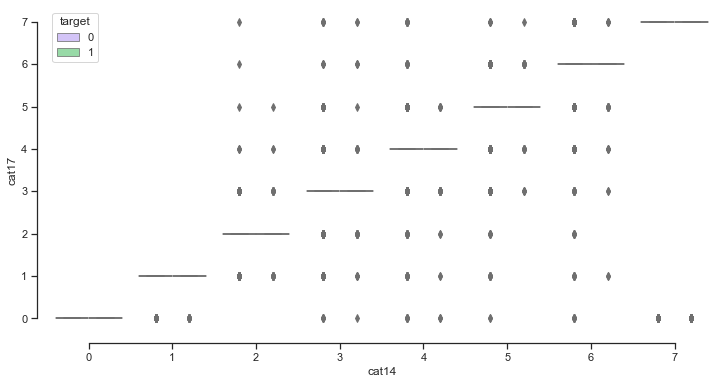

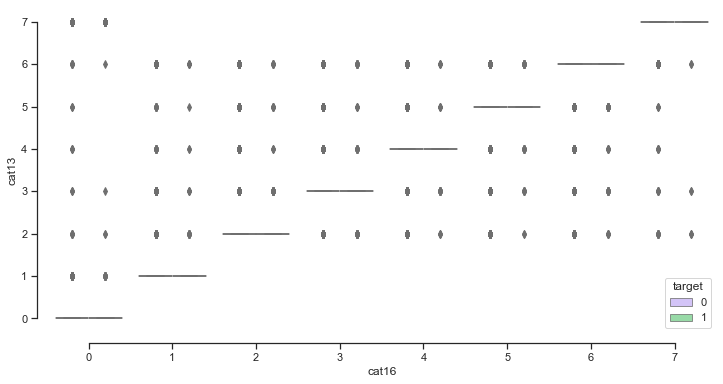

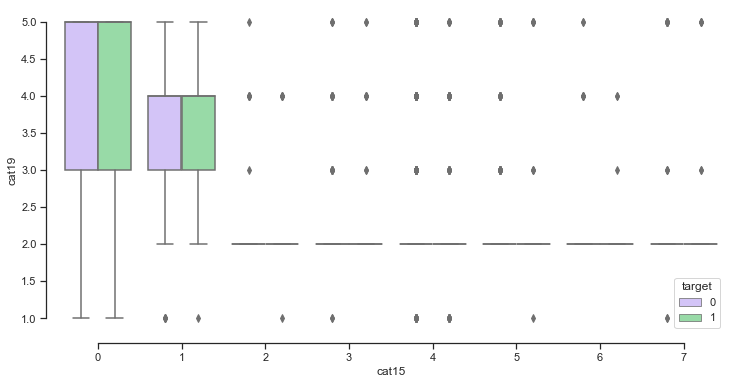

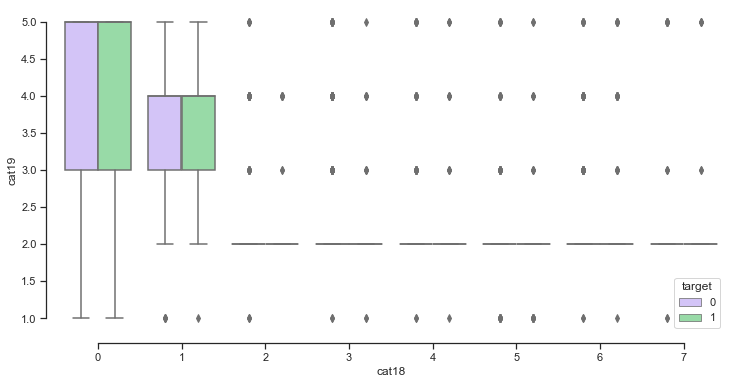

In [16]:
#STRONG CORRELATION
#positively correlated, corrletation: 0.95
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat14, y=df.cat17,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()


#positively correlated, corrletation: 0.92
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat16, y=df.cat13,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()




#negatively correlated, corrletation: -0.55
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat15, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()


#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat18, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [0.5, 10]
plt.show()

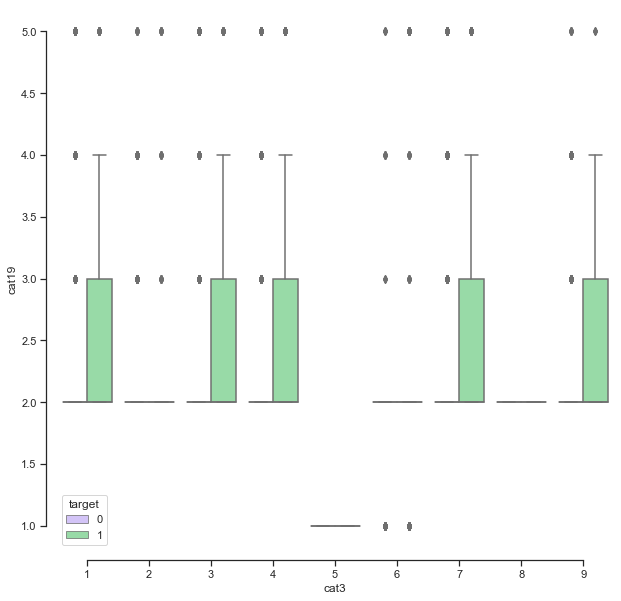

In [23]:
#very low correlated, corrletation: -0.0013
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat3, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [10, 20]
plt.show()





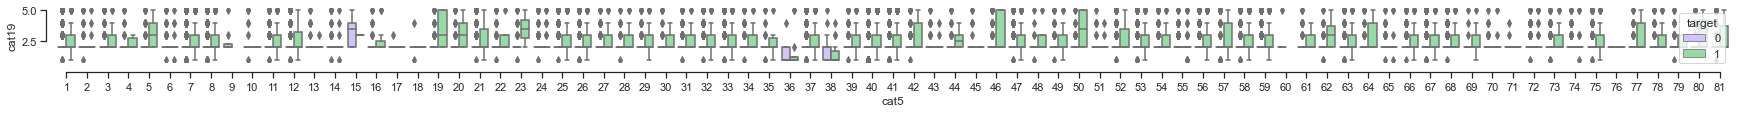

In [41]:

#very low correlated, corrletation: -0.0009
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat5, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [0, 1]
plt.show()


NUMERICAL VARIABLES

HISTOGRAMS

In [42]:
#define a function to get histogram of each column
def plot_histo(cstr, column):
    plt.hist(column)
    plt.title(cstr)
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.show()  
    
    # Add title and axis names


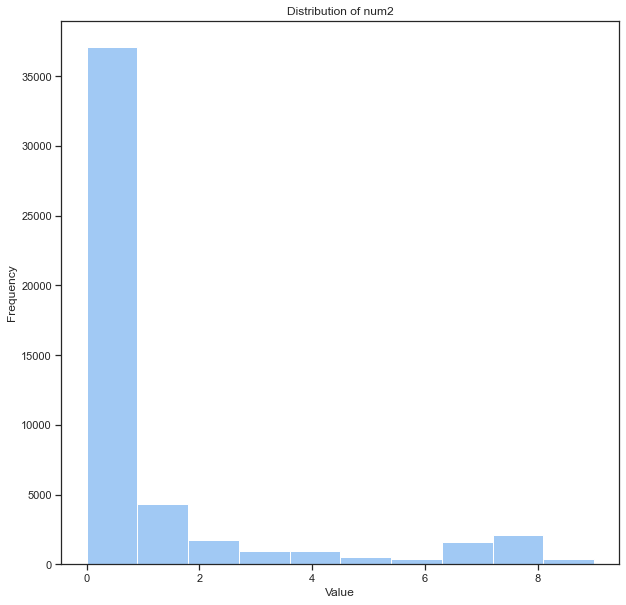

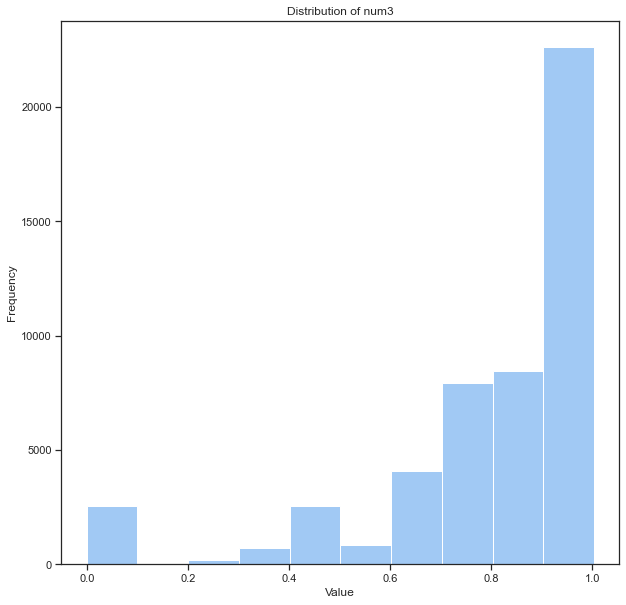

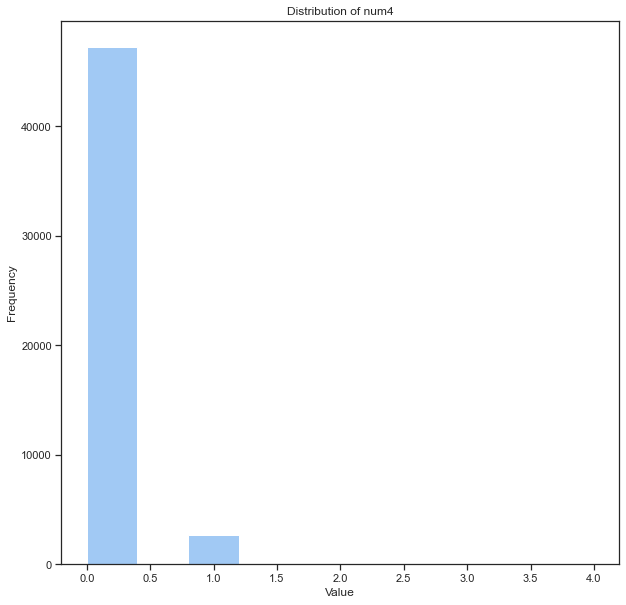

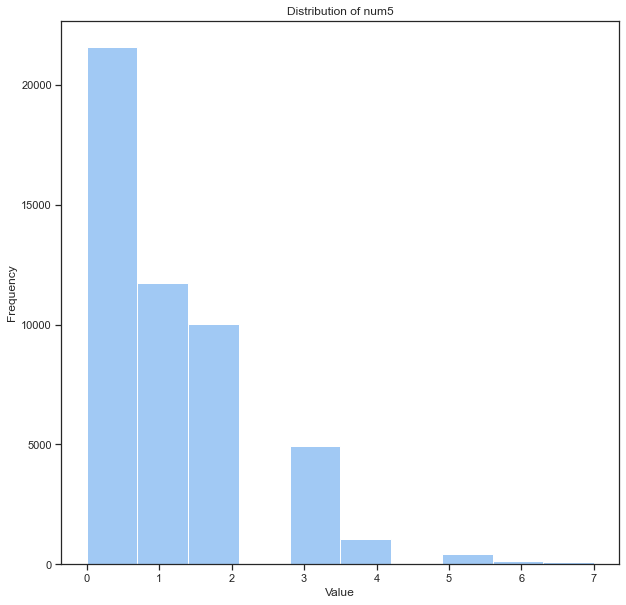

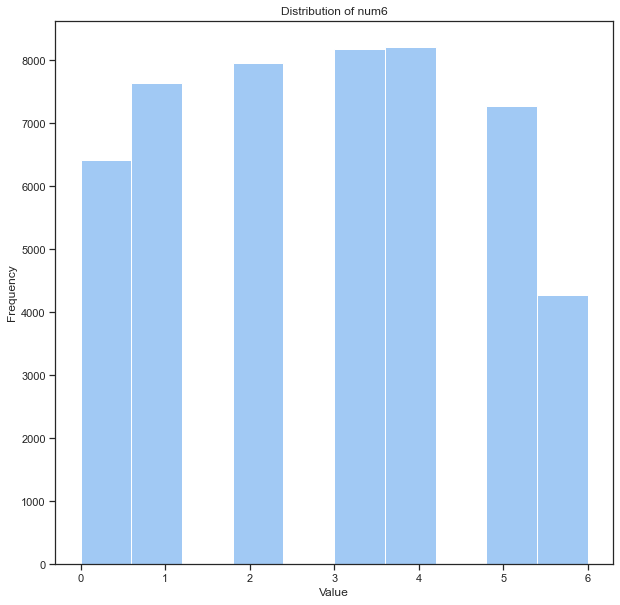

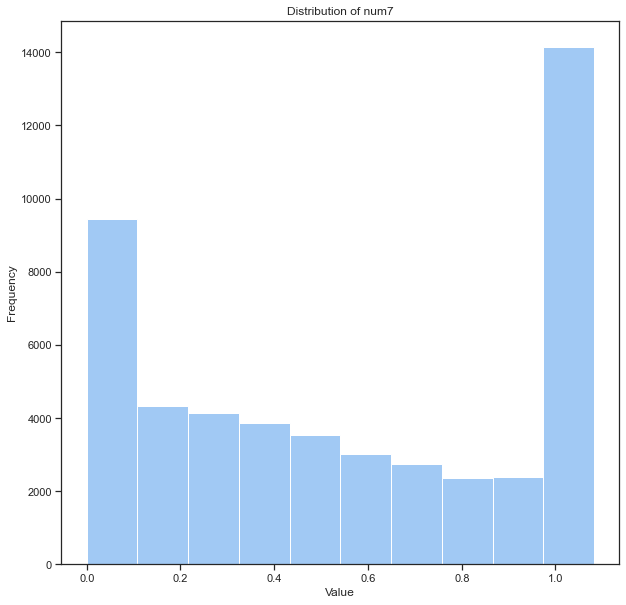

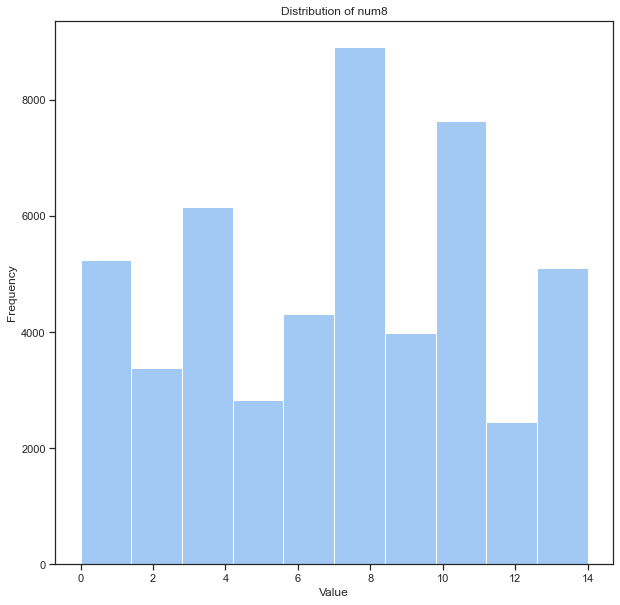

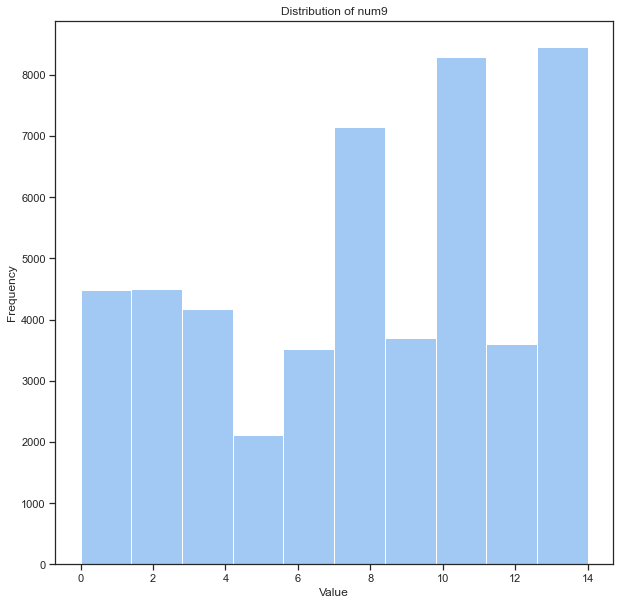

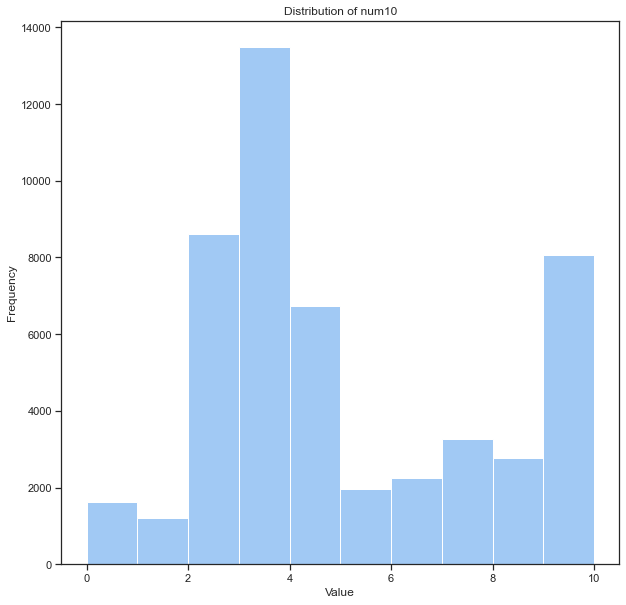

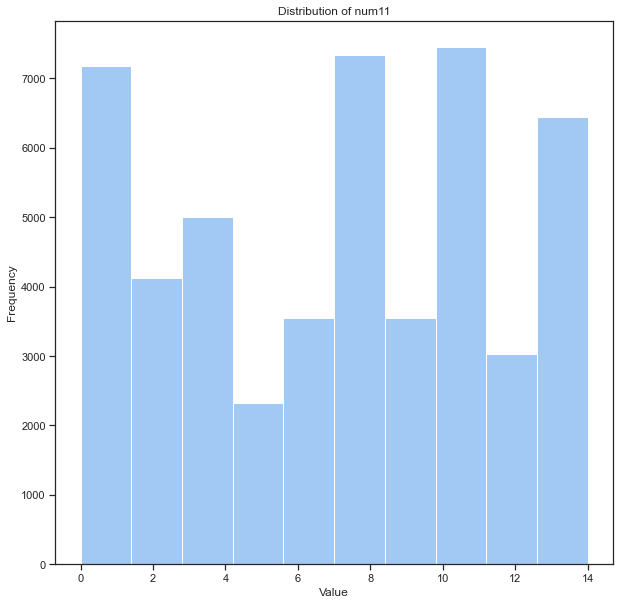

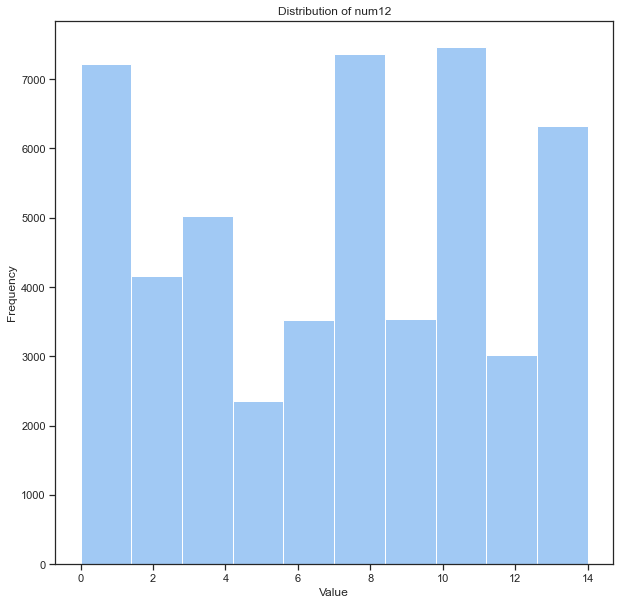

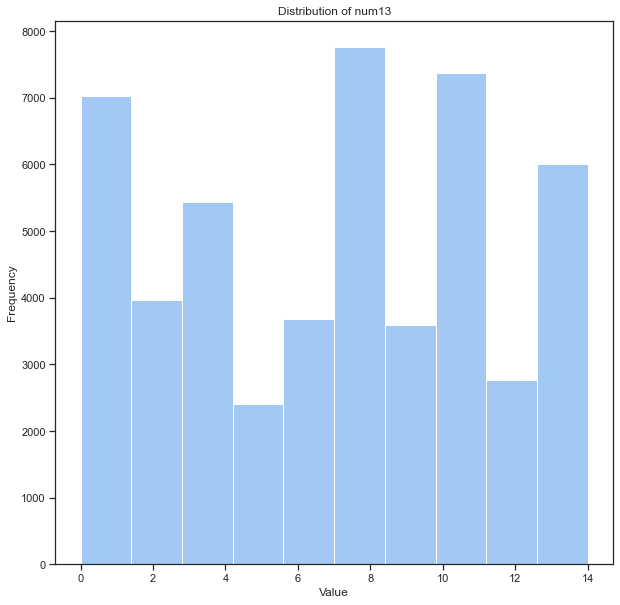

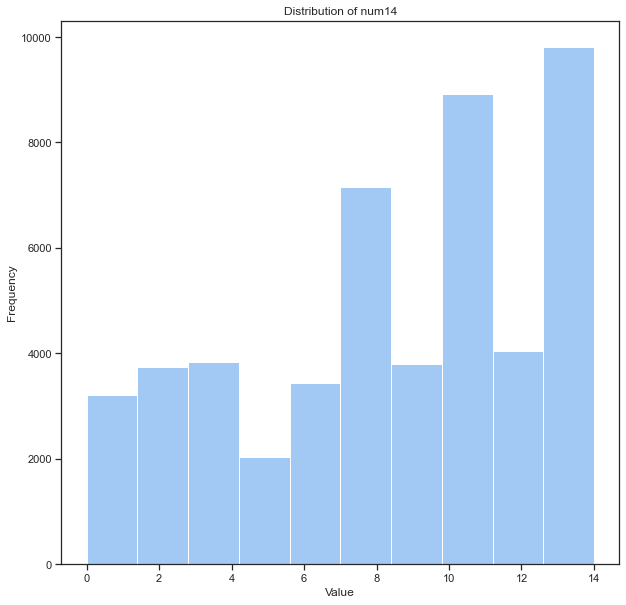

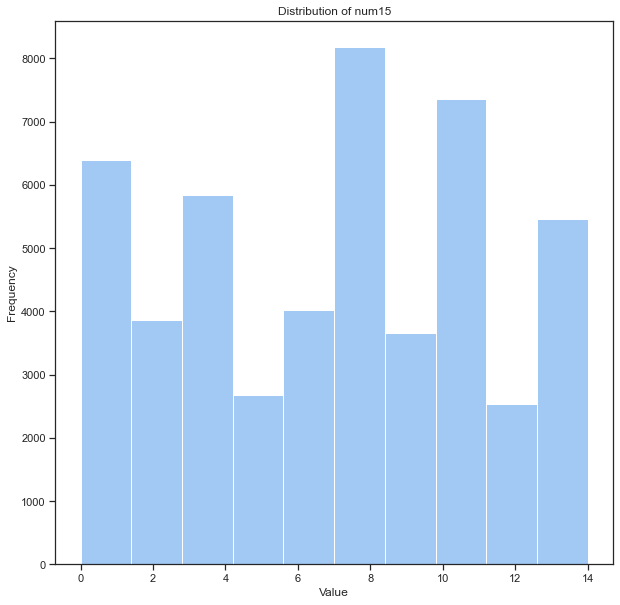

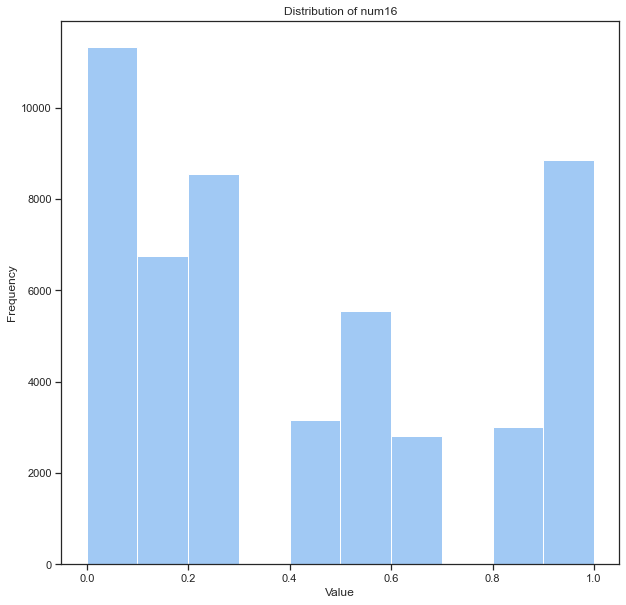

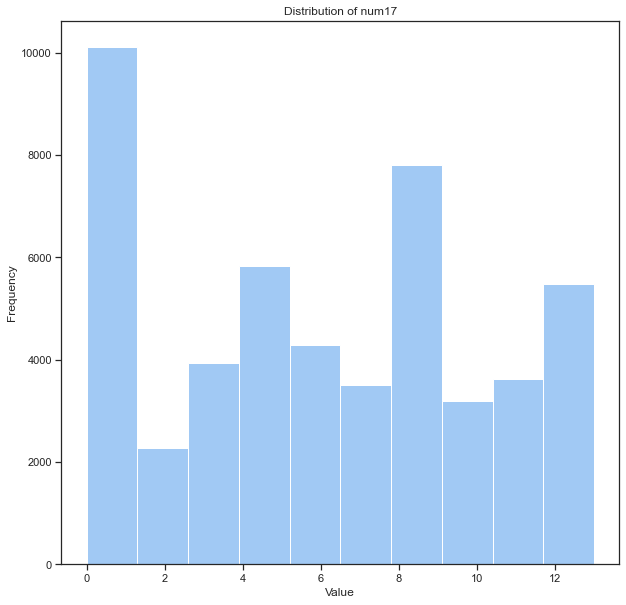

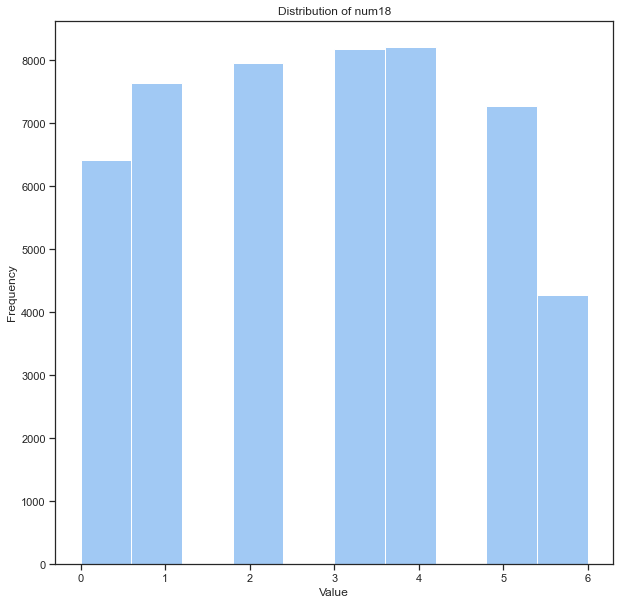

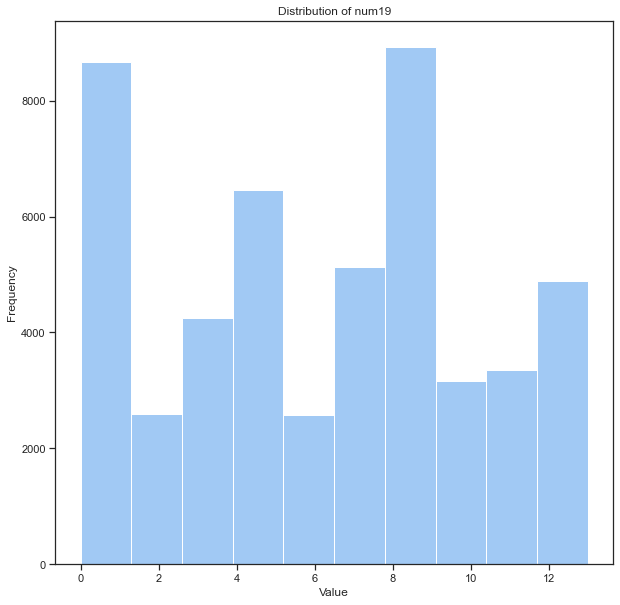

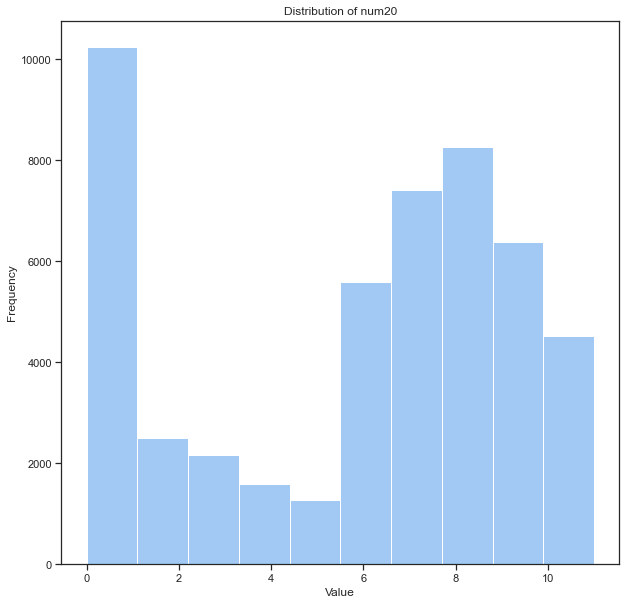

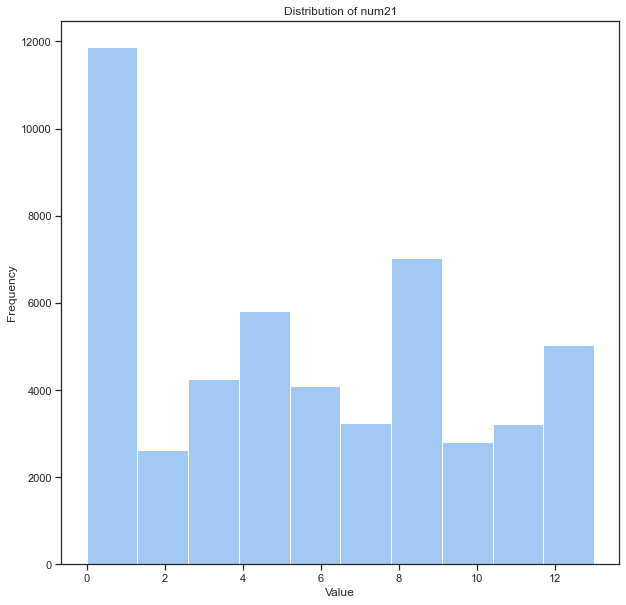

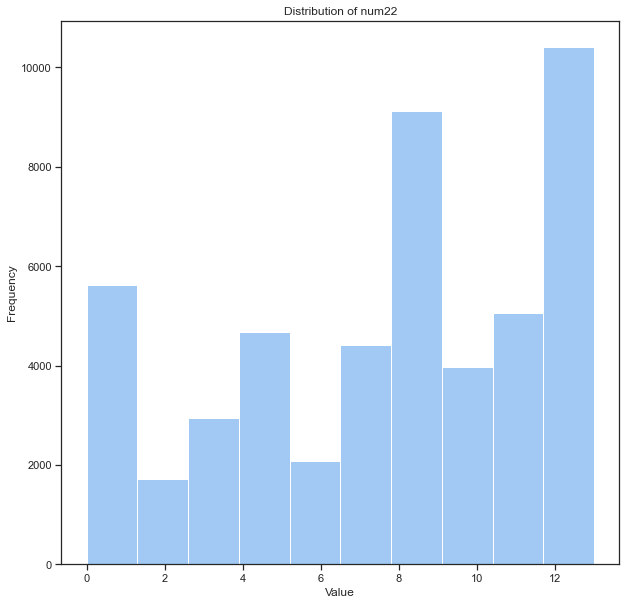

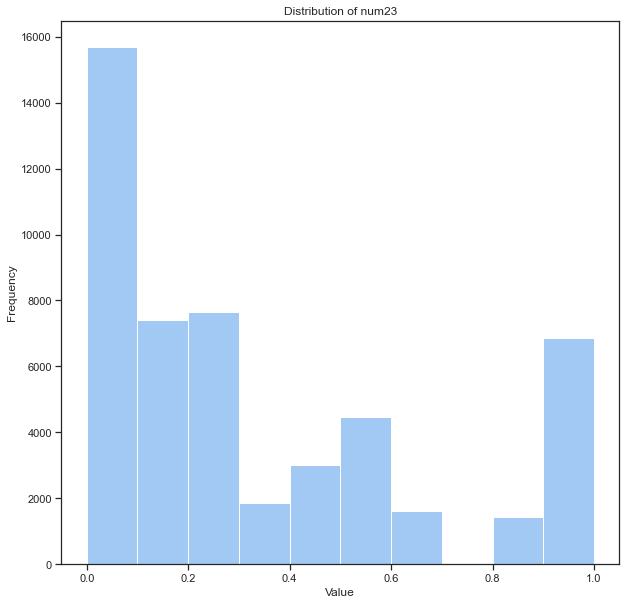

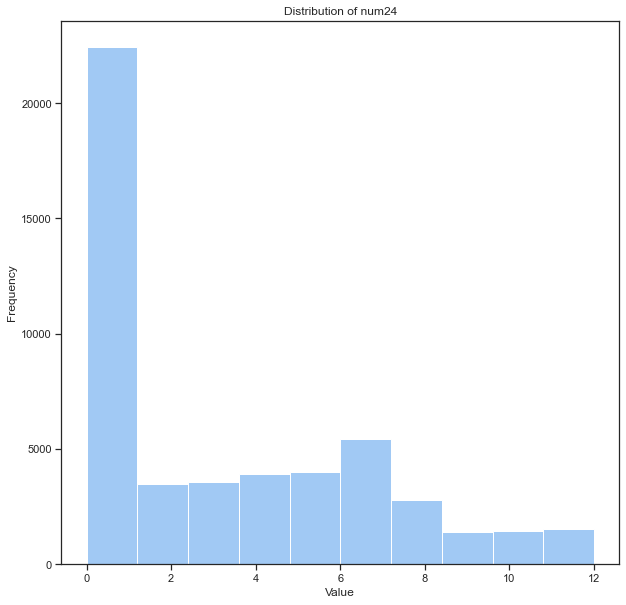

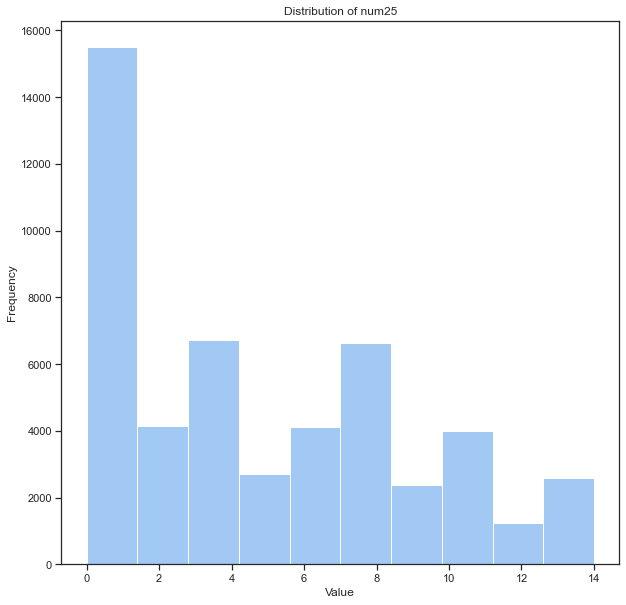

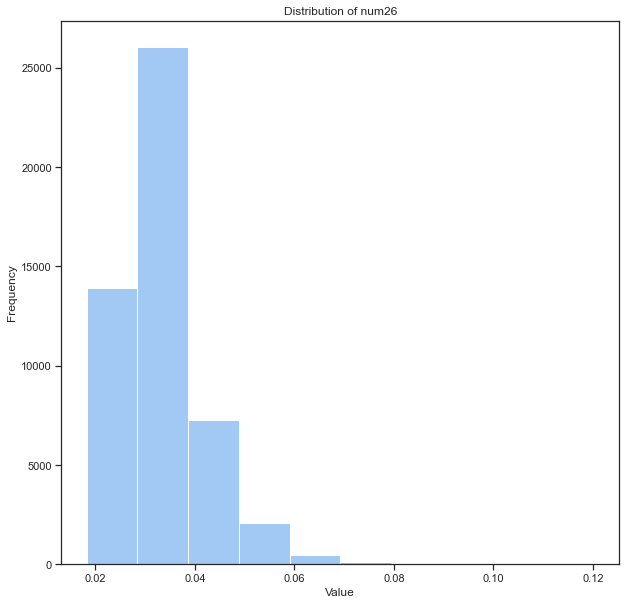

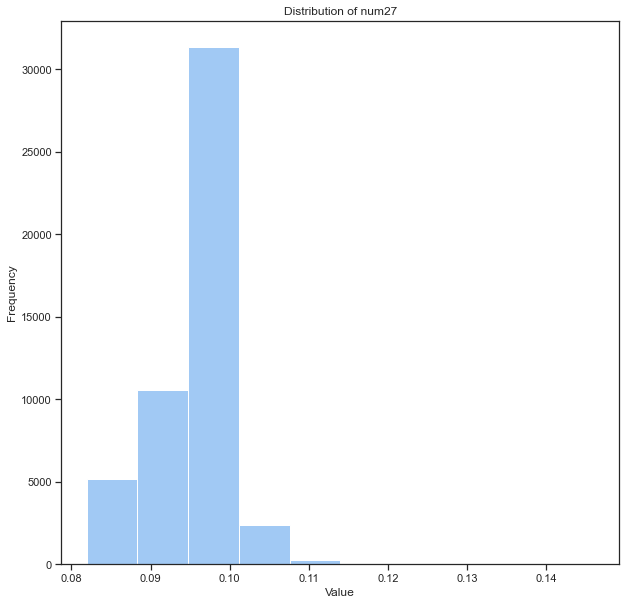

In [49]:
#numeric variables
#histo plot for numeric variables
df.num1.describe()
plt.rcParams["figure.figsize"] = [10, 10]


df.num2.describe()
plot_histo("Distribution of num2", df.num2)

df.num3.describe()
plot_histo("Distribution of num3", df.num3)

df.num4.describe()
plot_histo("Distribution of num4", df.num4)

df.num5.describe()
plot_histo("Distribution of num5", df.num5)

df.num6.describe()
plot_histo("Distribution of num6", df.num6)

df.num7.describe()
plot_histo("Distribution of num7", df.num7)

df.num8.describe()
plot_histo("Distribution of num8", df.num8)

df.num9.describe()
plot_histo("Distribution of num9", df.num9)

df.num10.describe()
plot_histo("Distribution of num10", df.num10)

df.num11.describe()
plot_histo("Distribution of num11", df.num11)

df.num12.describe()
plot_histo("Distribution of num12", df.num12)

df.num13.describe()
plot_histo("Distribution of num13", df.num13)

df.num14.describe()
plot_histo("Distribution of num14", df.num14)

df.num15.describe()
plot_histo("Distribution of num15", df.num15)

df.num16.describe()
plot_histo("Distribution of num16", df.num16)

df.num17.describe()
plot_histo("Distribution of num17", df.num17)

df.num18.describe()
plot_histo("Distribution of num18", df.num18)

df.num19.describe()
plot_histo("Distribution of num19", df.num19)

df.num20.describe()
plot_histo("Distribution of num20", df.num20)

df.num21.describe()
plot_histo("Distribution of num21", df.num21)

df.num22.describe()
plot_histo("Distribution of num22", df.num22)

df.num23.describe()
plot_histo("Distribution of num23", df.num23)

df.num24.describe()
plot_histo("Distribution of num24", df.num24)

df.num25.describe()
plot_histo("Distribution of num25", df.num25)

df.num26.describe()
plot_histo("Distribution of num26", df.num26)

df.num27.describe()
plot_histo("Distribution of num27", df.num27)




HEAT MAP FOR NUMERIC VARIABLES

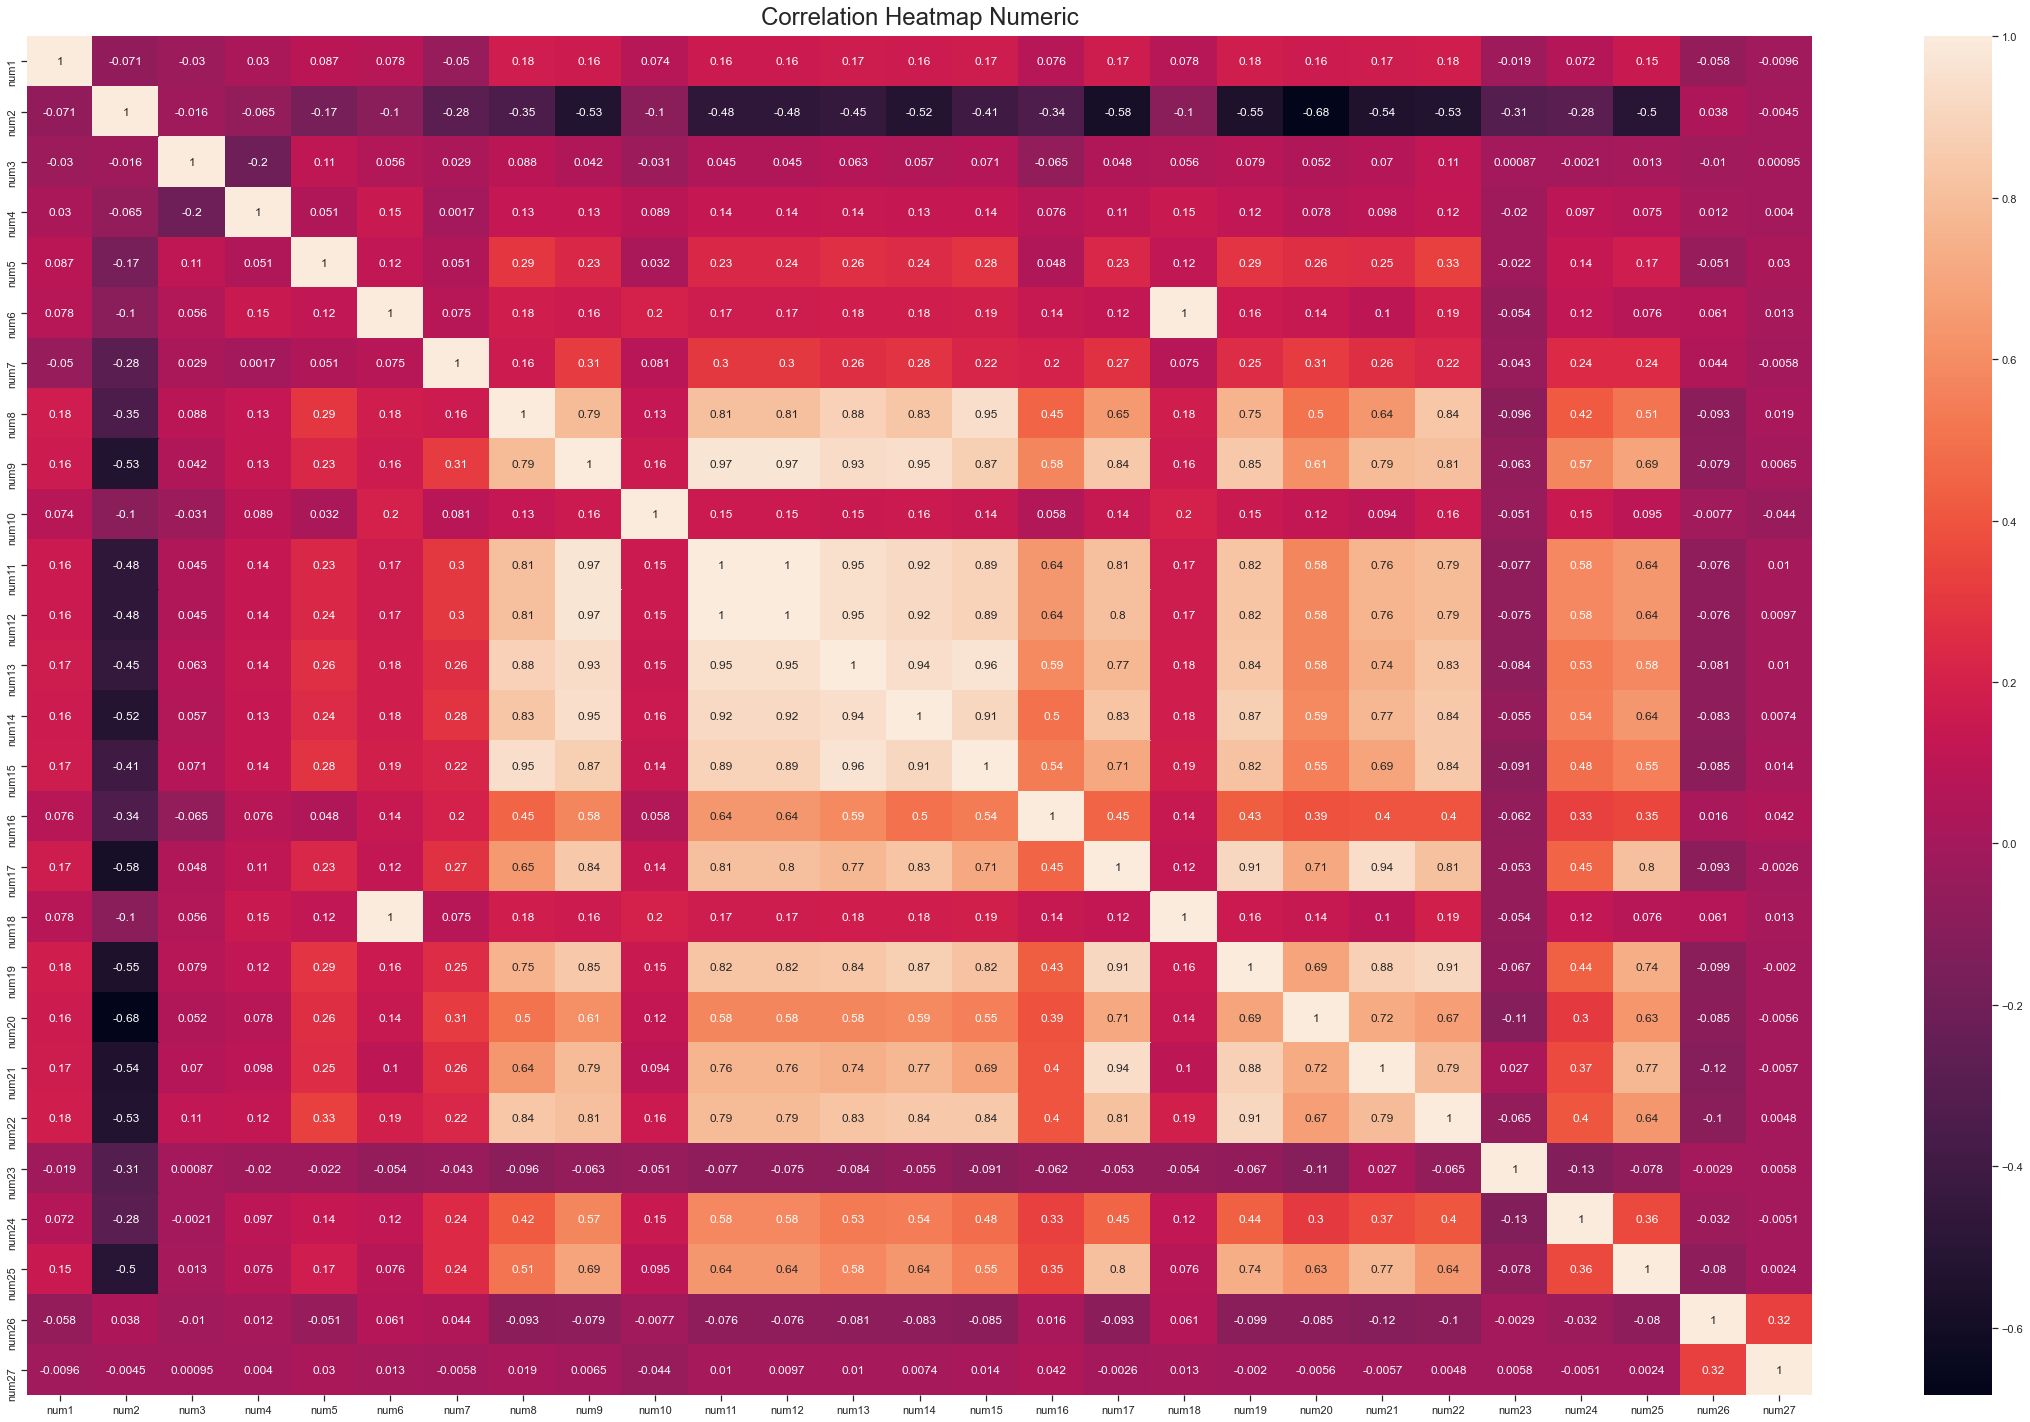

In [50]:
#heat map only for numeric variables
data_num = df.iloc[:,20:47]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data_num.corr(), annot=True,yticklabels=data_num.columns,xticklabels=data_num.columns)
heatmap.set_title('Correlation Heatmap Numeric', fontdict={'fontsize':24}, pad=12);

BOX PLOT FOR NUMERIC VARIABLES

<ipython-input-51-bd0a124ff644>:81: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(10, 5))


Text(0.5, 1.0, 'TARGET')

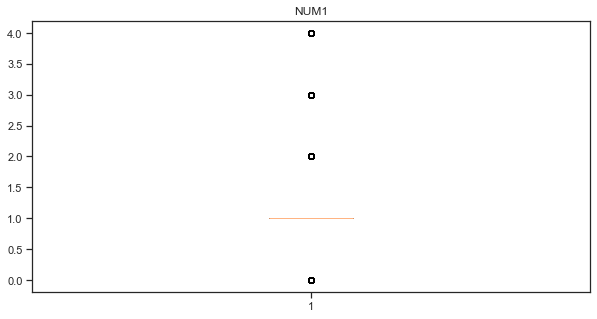

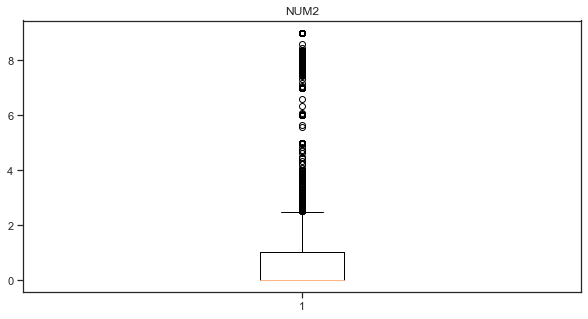

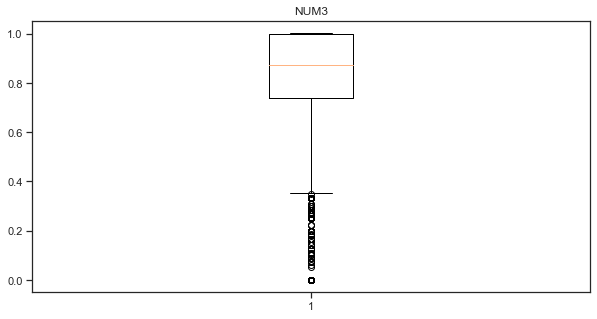

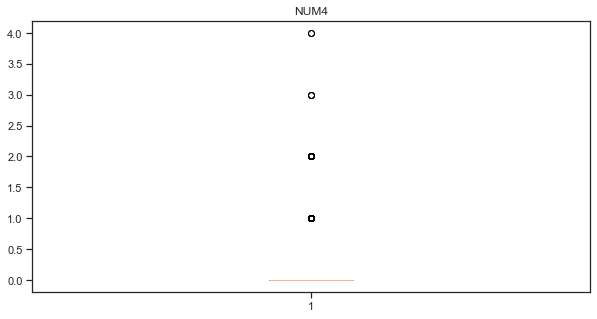

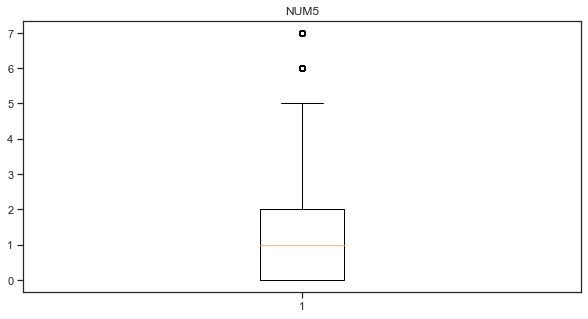

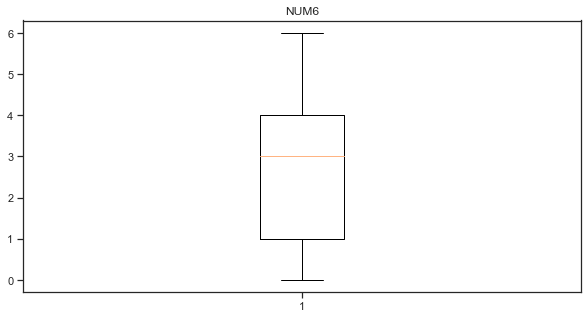

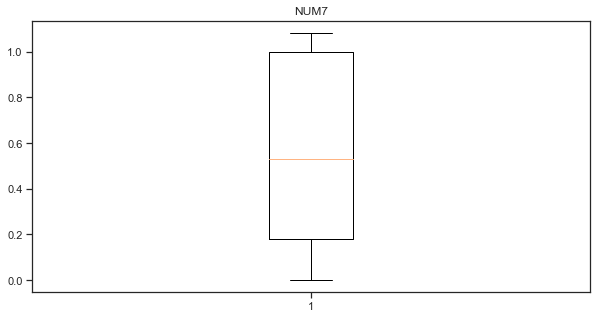

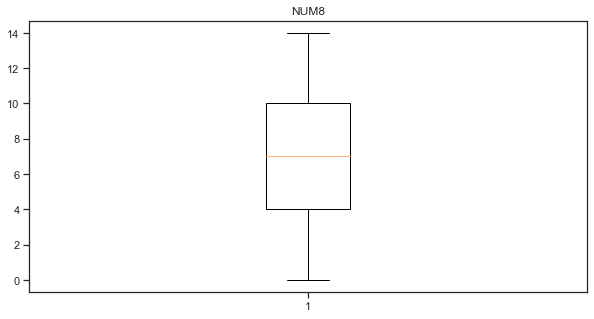

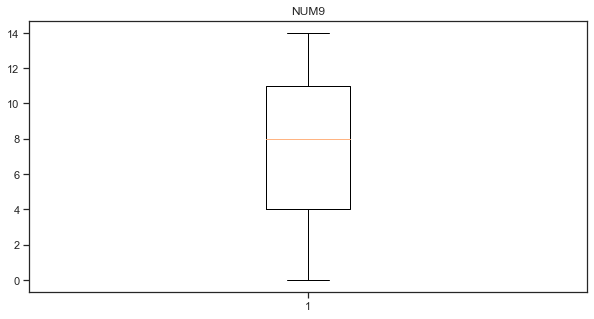

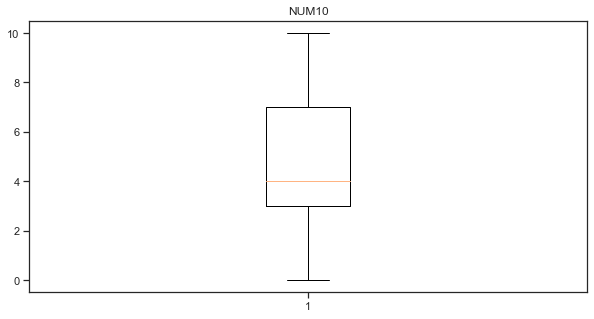

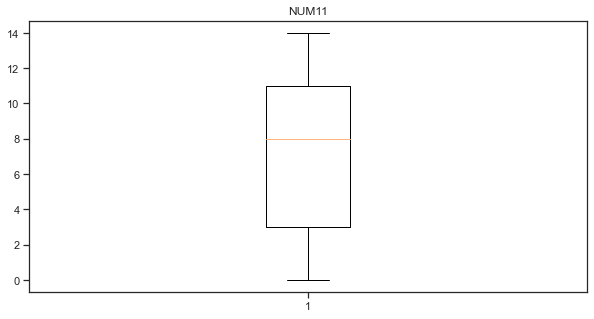

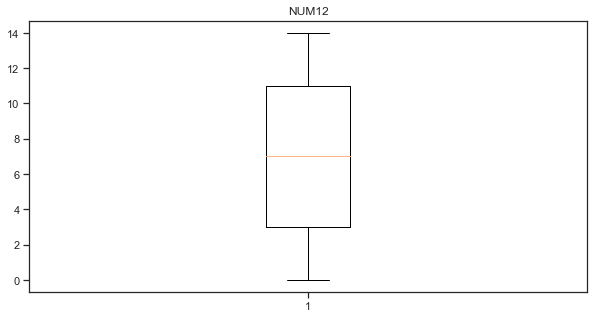

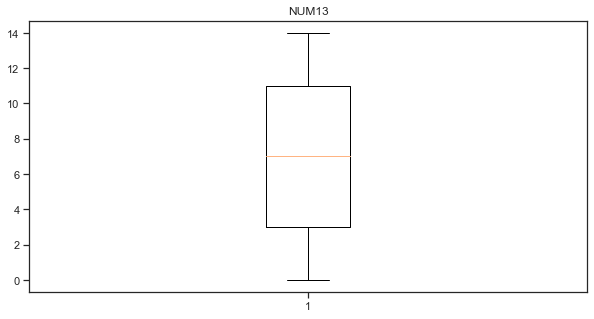

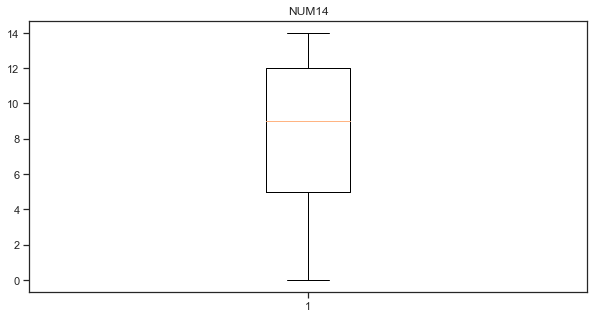

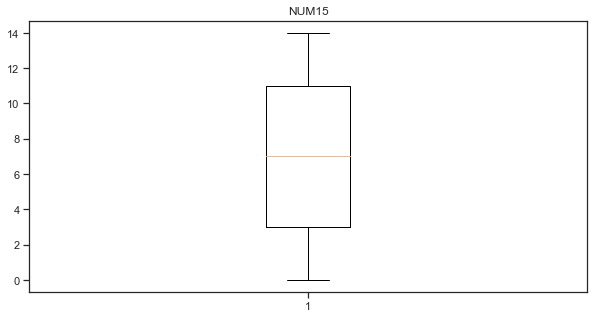

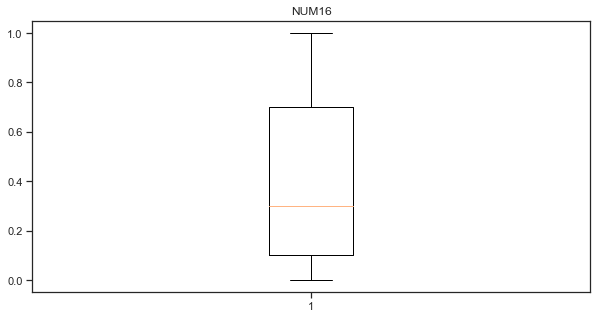

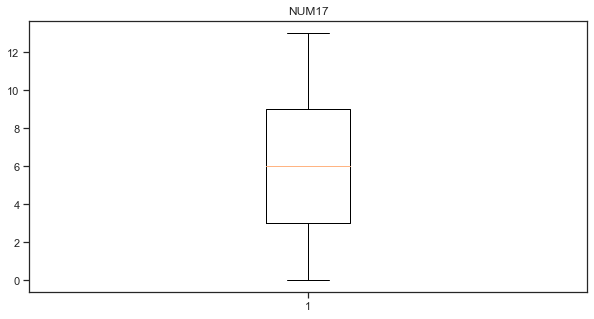

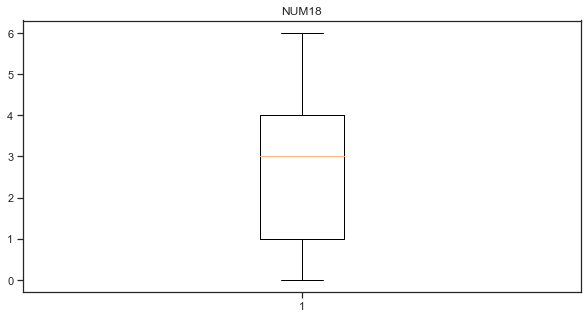

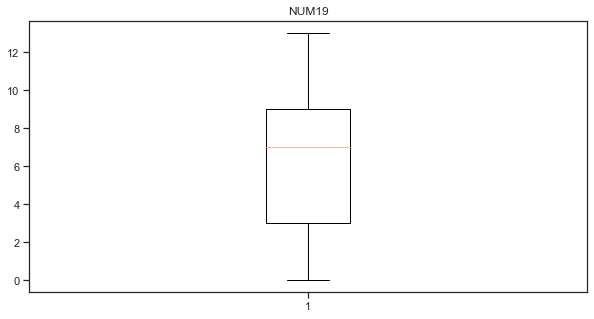

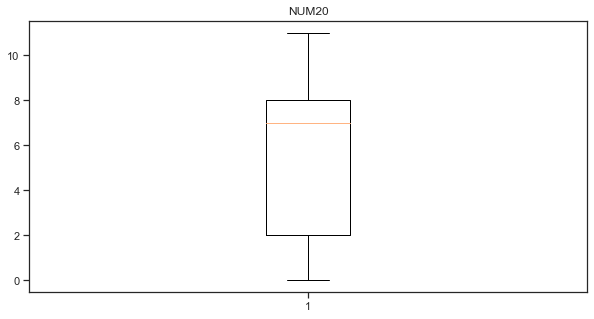

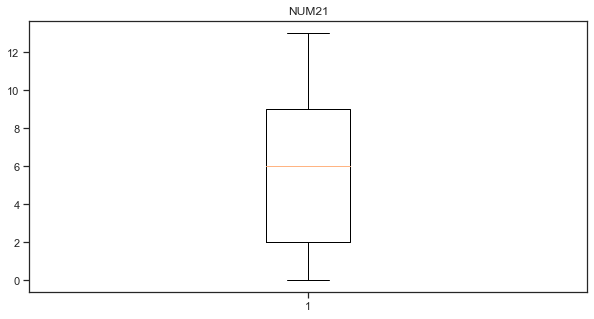

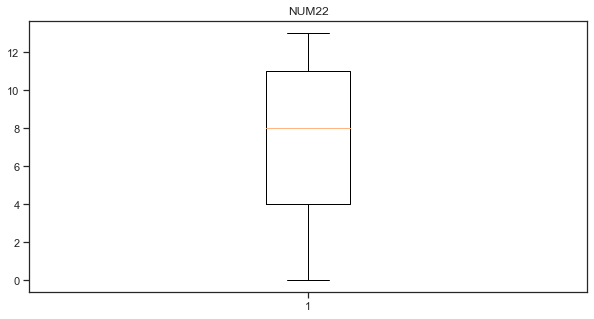

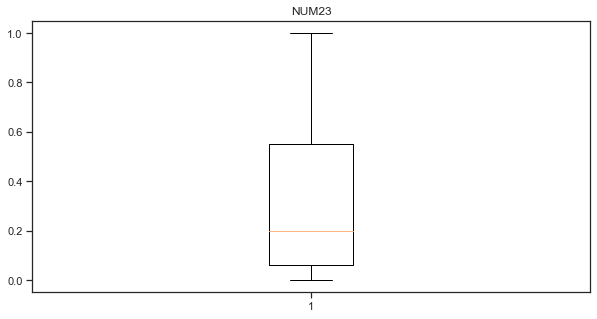

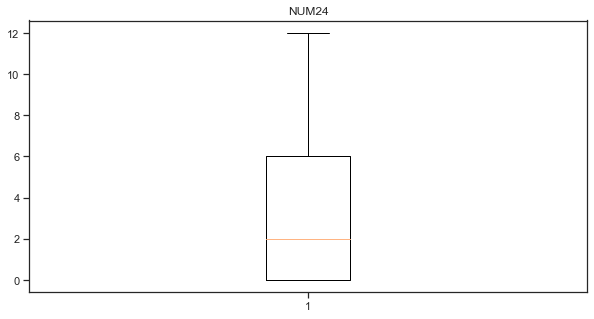

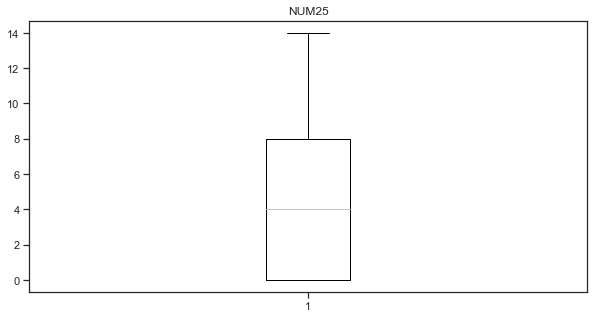

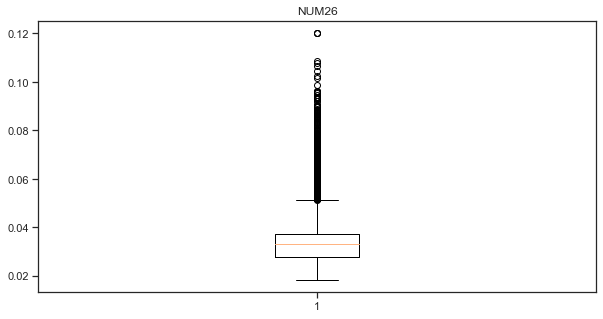

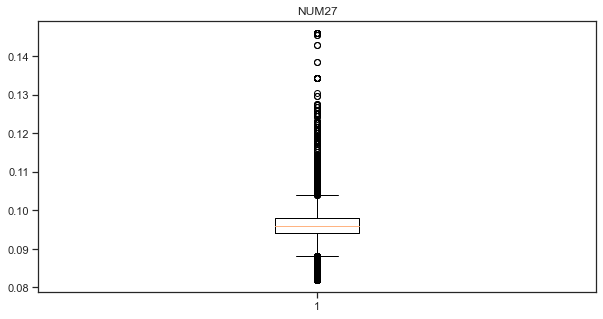

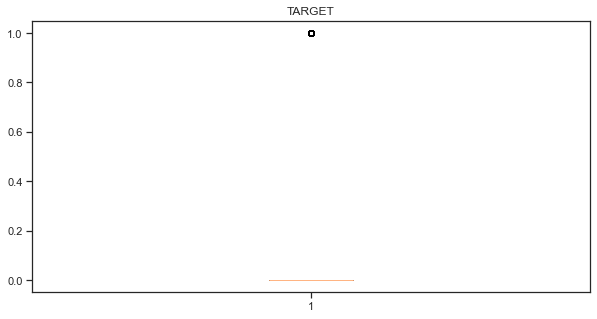

In [51]:


plt.figure(figsize=(10, 5))
plt.boxplot(df['num1'])
plt.title('NUM1')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num2'])
plt.title('NUM2')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num3'])
plt.title('NUM3')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num4'])
plt.title('NUM4')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num5'])
plt.title('NUM5')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num6'])
plt.title('NUM6')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num7'])
plt.title('NUM7')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num8'])
plt.title('NUM8')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num9'])
plt.title('NUM9')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num10'])
plt.title('NUM10')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num11'])
plt.title('NUM11')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num12'])
plt.title('NUM12')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num13'])
plt.title('NUM13')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num14'])
plt.title('NUM14')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num15'])
plt.title('NUM15')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num16'])
plt.title('NUM16')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num17'])
plt.title('NUM17')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num18'])
plt.title('NUM18')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num19'])
plt.title('NUM19')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num20'])
plt.title('NUM20')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num21'])
plt.title('NUM21')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num22'])
plt.title('NUM22')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num23'])
plt.title('NUM23')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num24'])
plt.title('NUM24')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num25'])
plt.title('NUM25')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num26'])
plt.title('NUM26')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num27'])
plt.title('NUM27')

plt.figure(figsize=(10, 5))
plt.boxplot(df['target'])
plt.title('TARGET')





SCATTERPLOT FOR NUMERIC X NUMERIC

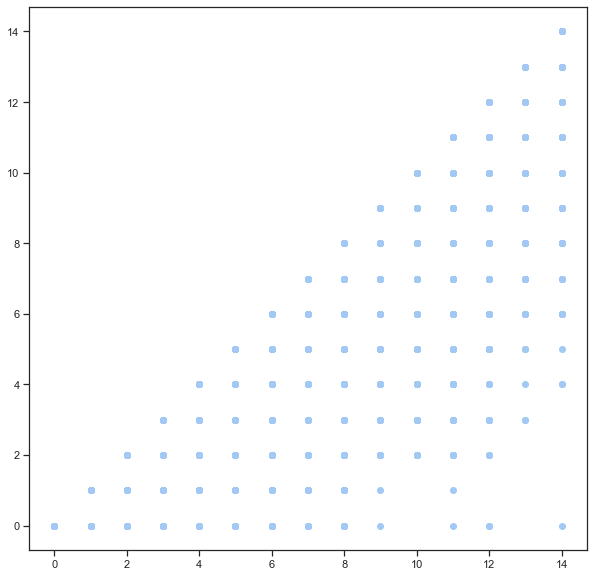

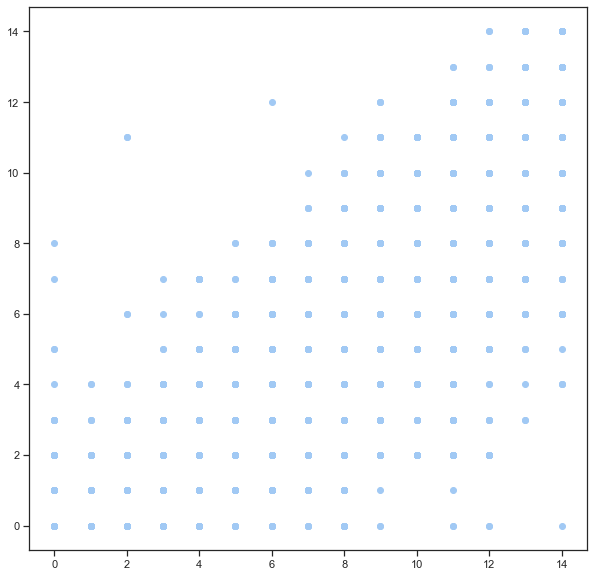

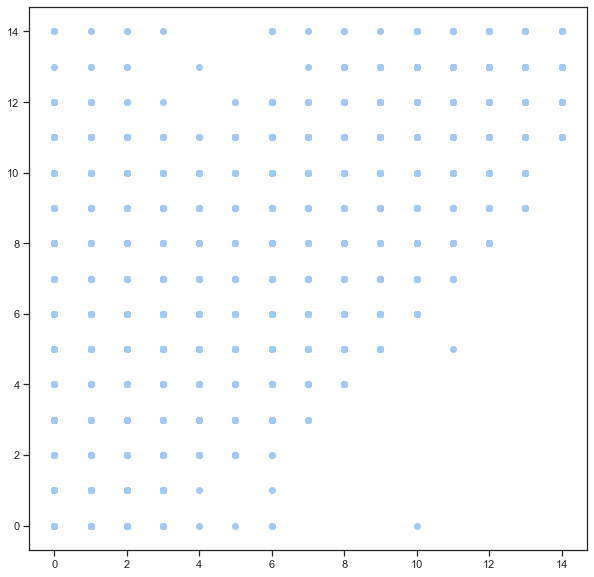

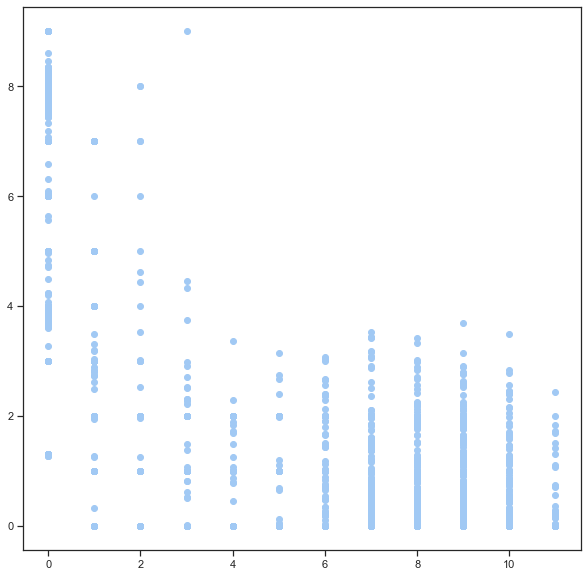

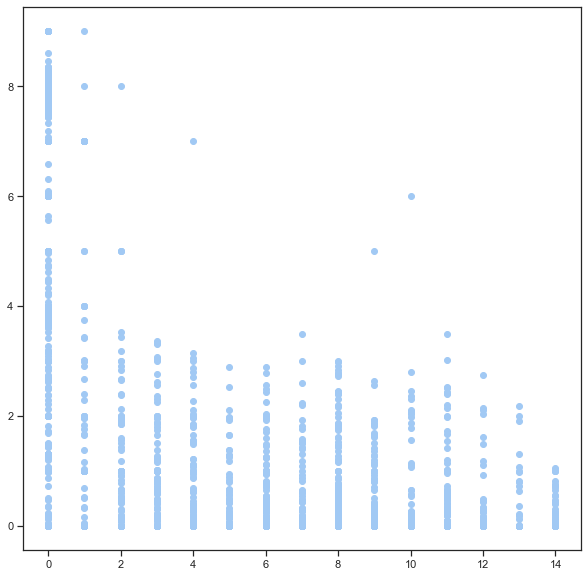

In [52]:
#for variables with strong correlation (close to 1 in absolute value)
plt.scatter(data_num['num9'], data_num['num11'])
plt.show()
#CORRELASYON 0.97

plt.scatter(data_num['num9'], data_num['num12'])
plt.show()
#CORRELASYON 0.97

plt.scatter(data_num['num11'], data_num['num13'])
plt.show()
#CORRELASYON 0.95

plt.scatter(data_num['num20'], data_num['num2'])
plt.show()
#CORRELASYON -0.68 DEĞİŞTİ

plt.scatter(data_num['num25'], data_num['num2'])
plt.show()
#CORRELASYON -0.5 DEĞİŞTİ

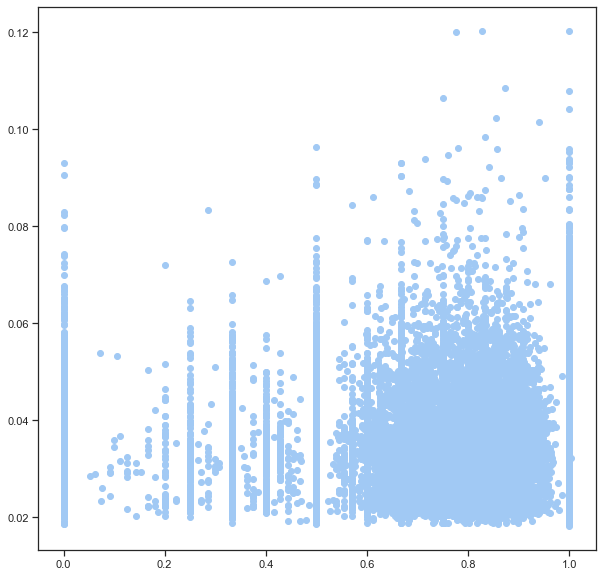

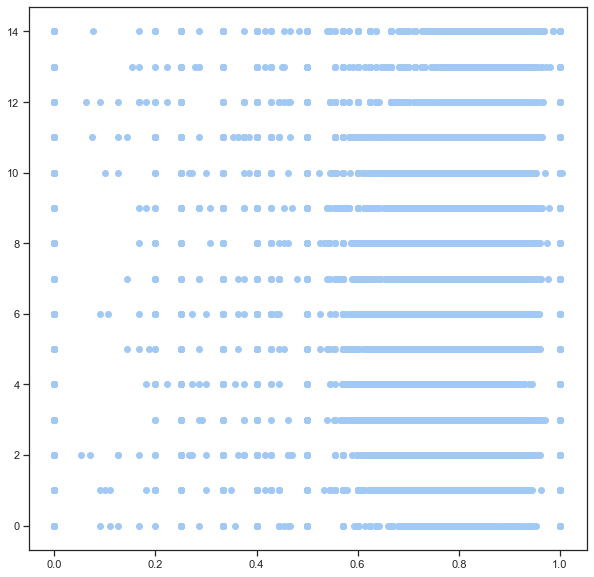

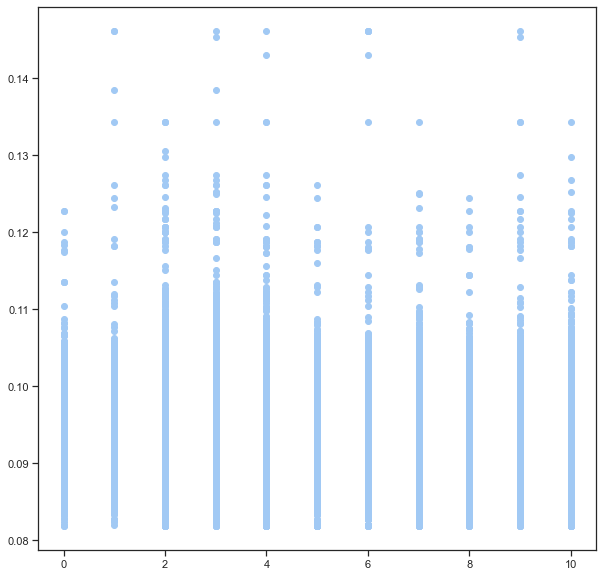

In [53]:

#for variables with weak correlation (close to 0 in absolute value)
plt.scatter(data_num['num3'], data_num['num26'])
plt.show()
#CORRELASYON -0.01 DEĞİŞTİ

plt.scatter(data_num['num3'], data_num['num13'])
plt.show()
#CORRELASYON 0.063 DEĞİŞTİ

plt.scatter(data_num['num10'], data_num['num27'])
plt.show()
#CORRELASYON 0.044 DEĞİŞTİ

KeyboardInterrupt: 

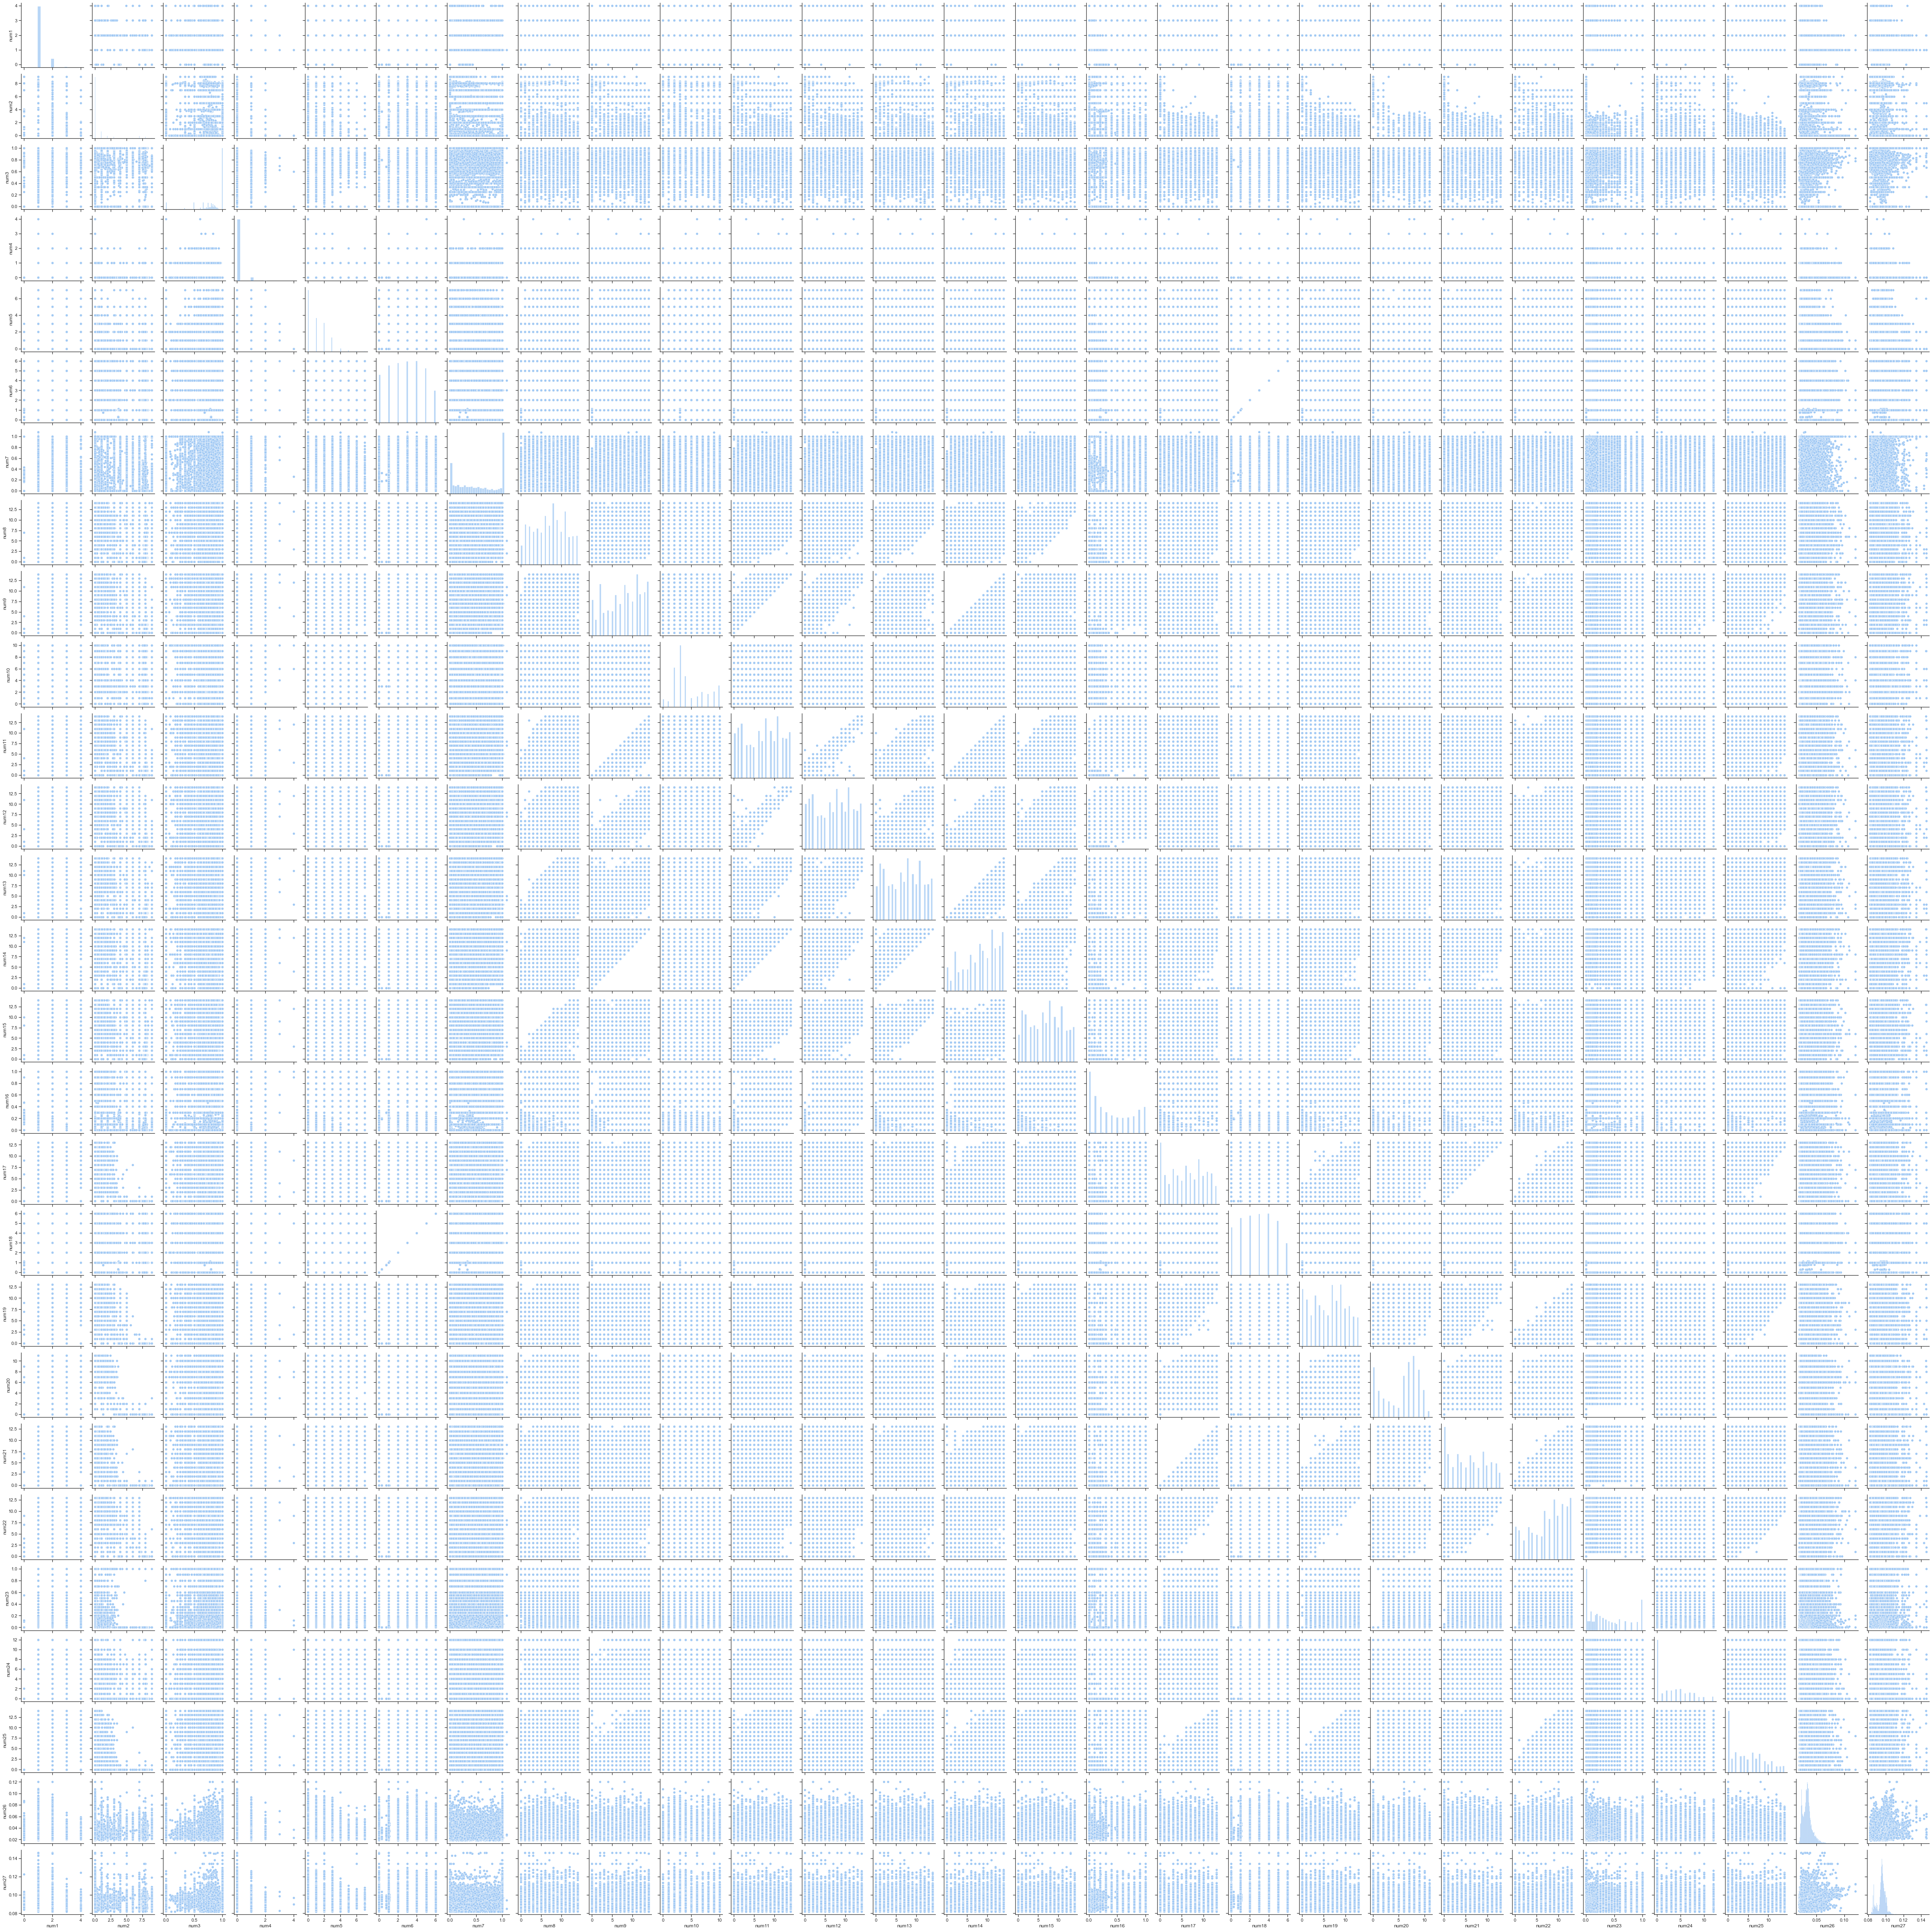

In [54]:
sns.pairplot(data_num)

HEAT MAP FOR ALL VARIABLES

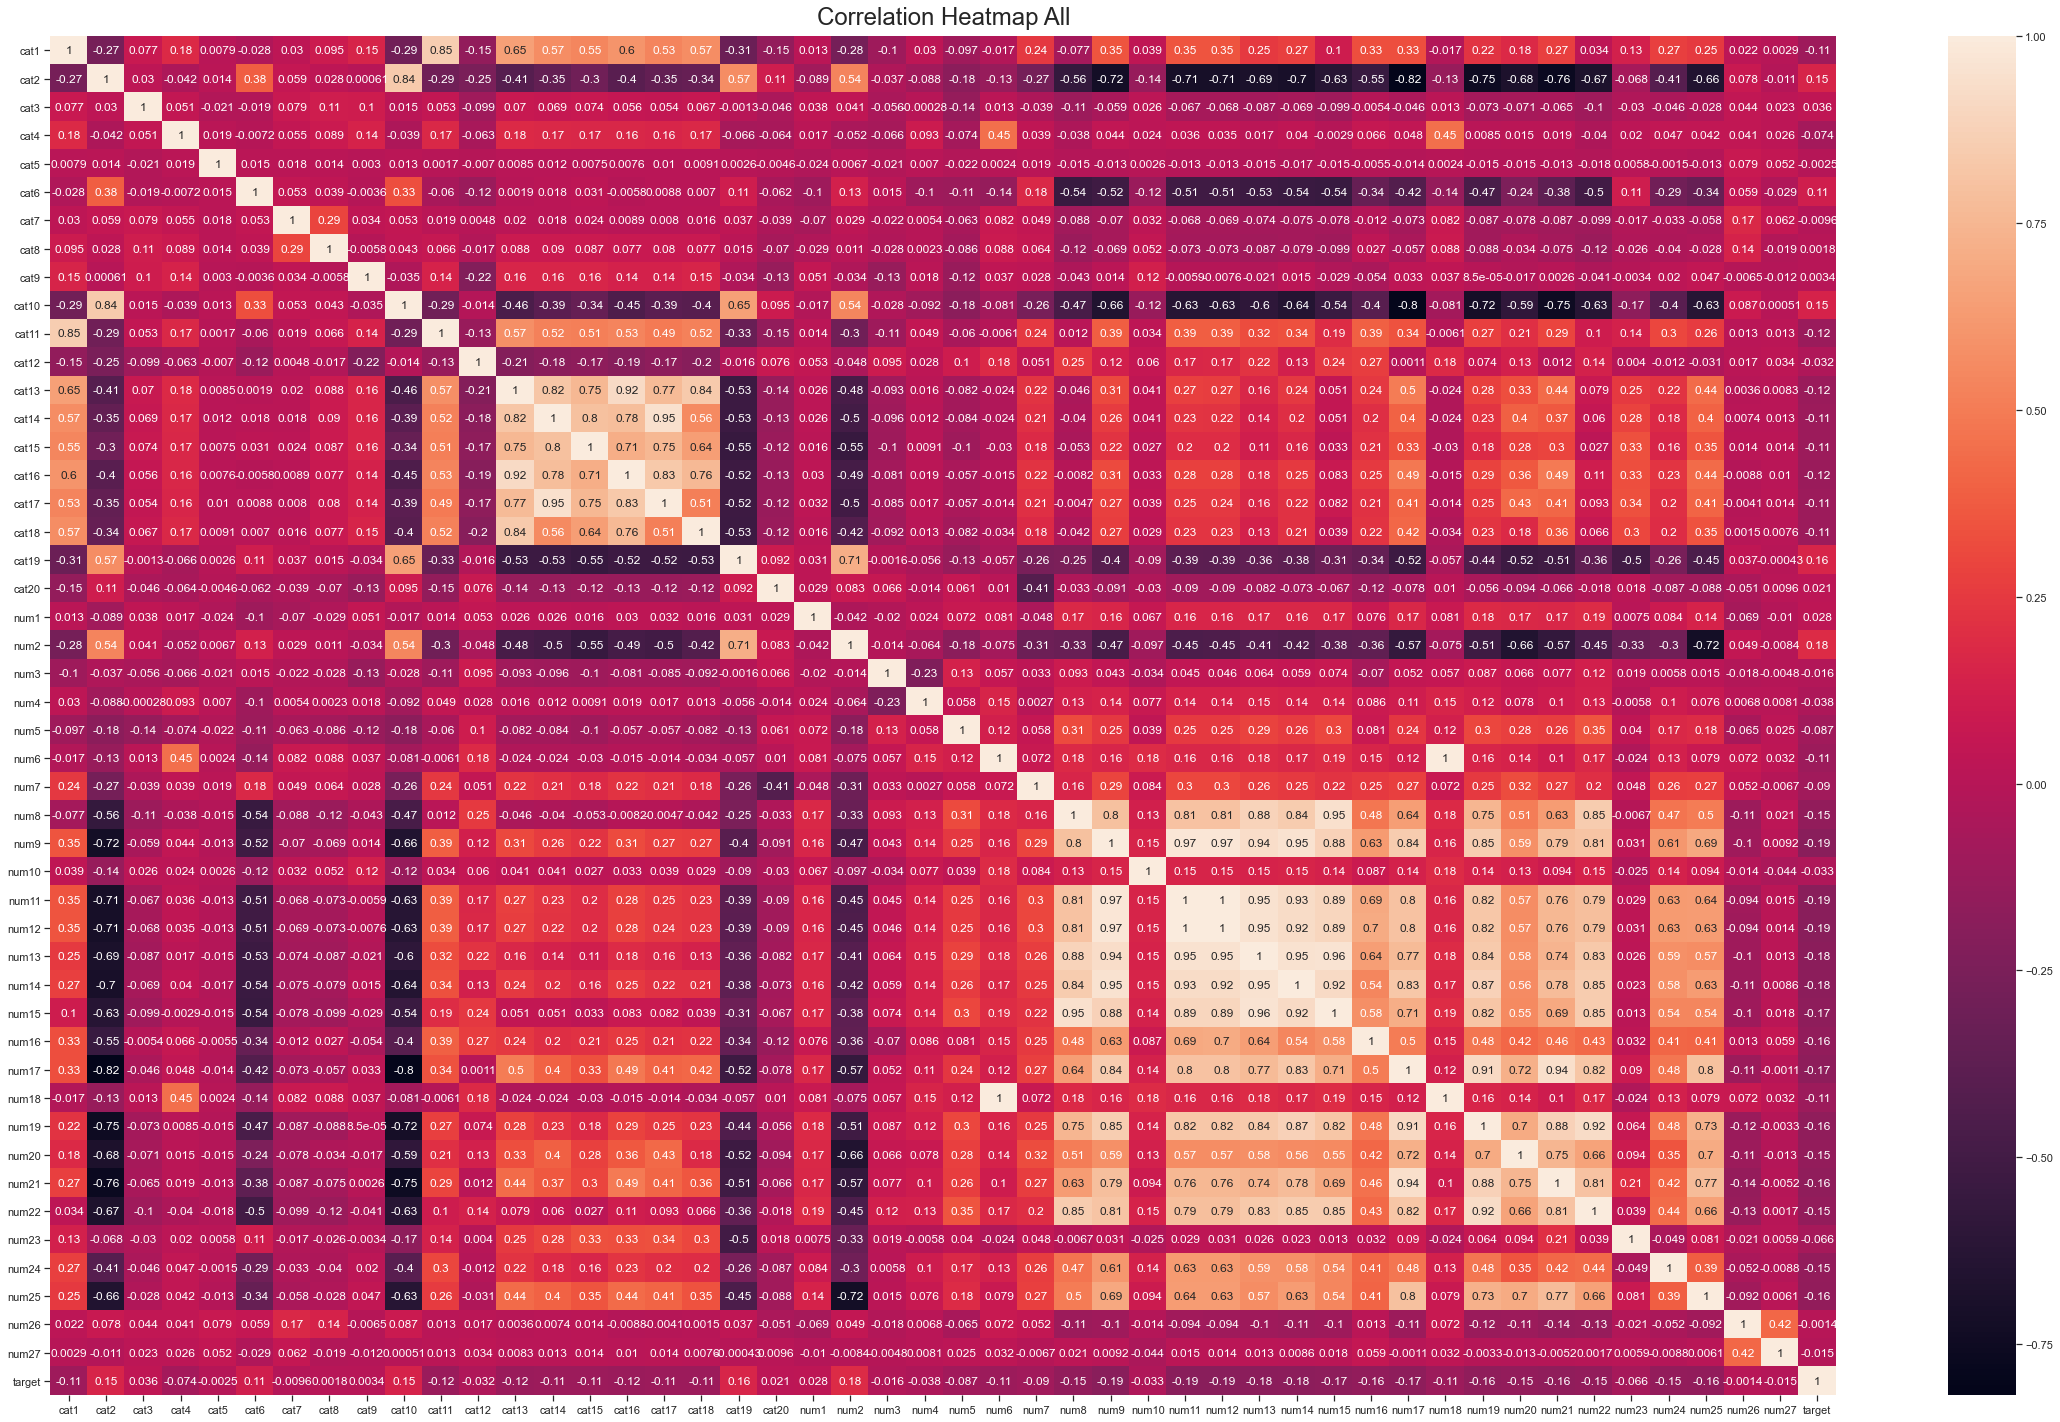

In [55]:
data = df.iloc[:,0:48]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data.corr(method='spearman'), annot=True,yticklabels=data.columns,xticklabels=data.columns)
heatmap.set_title('Correlation Heatmap All', fontdict={'fontsize':24}, pad=12);

In [56]:
#HEAT-MAP
correlation_matrix = df.corr()
df.corr()

,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,...,num19,num20,num21,num22,num23,num24,num25,num26,num27,target
cat1,1.000000,-0.359436,0.059039,0.171668,0.005422,-0.049628,0.038314,0.082608,0.134227,-0.328001,...,0.268403,0.242965,0.297517,0.106997,0.107277,0.288385,0.263774,0.013168,-0.004545,-0.126641
cat2,-0.359436,1.000000,0.039606,-0.057904,0.012822,0.334457,0.040286,0.034049,-0.004940,0.805824,...,-0.764348,-0.747277,-0.774914,-0.703718,-0.018568,-0.390512,-0.644711,0.063911,-0.005993,0.176784
cat3,0.059039,0.039606,1.000000,0.050654,-0.027051,-0.017892,0.087566,0.119588,0.088289,0.022643,...,-0.068275,-0.065411,-0.059482,-0.099956,-0.007480,-0.035048,-0.020156,0.037399,0.002211,0.033498
cat4,0.171668,-0.057904,0.050654,1.000000,0.019585,-0.015747,0.055630,0.087244,0.137300,-0.044566,...,0.010058,0.024814,0.015467,-0.032015,0.017345,0.051709,0.040162,0.035864,0.011937,-0.074451
cat5,0.005422,0.012822,-0.027051,0.019585,1.000000,0.010677,0.010701,0.021364,0.003745,0.010880,...,-0.017306,-0.019874,-0.015889,-0.018987,0.009911,-0.002980,-0.014134,0.072151,0.037309,-0.001659
cat6,-0.049628,0.334457,-0.017892,-0.015747,0.010677,1.000000,0.000934,0.018614,0.007373,0.286260,...,-0.443943,-0.216863,-0.366292,-0.448184,0.133541,-0.268253,-0.350248,0.034943,-0.018090,0.120386
cat7,0.038314,0.040286,0.087566,0.055630,0.010701,0.000934,1.000000,0.307651,0.035037,0.029878,...,-0.042200,-0.061273,-0.042589,-0.057314,-0.000783,-0.016289,-0.020278,0.125321,0.035114,-0.008153
cat8,0.082608,0.034049,0.119588,0.087244,0.021364,0.018614,0.307651,1.000000,-0.010122,0.044742,...,-0.094245,-0.037597,-0.084278,-0.118225,-0.023890,-0.027568,-0.039121,0.107374,-0.062806,0.008860
cat9,0.134227,-0.004940,0.088289,0.137300,0.003745,0.007373,0.035037,-0.010122,1.000000,-0.031474,...,-0.013143,-0.018895,-0.003782,-0.059794,0.010092,0.023126,0.045402,-0.001728,-0.010370,0.003345
cat10,-0.328001,0.805824,0.022643,-0.044566,0.010880,0.286260,0.029878,0.044742,-0.031474,1.000000,...,-0.687578,-0.580584,-0.712682,-0.601188,-0.122884,-0.360829,-0.592874,0.068246,0.003011,0.150099


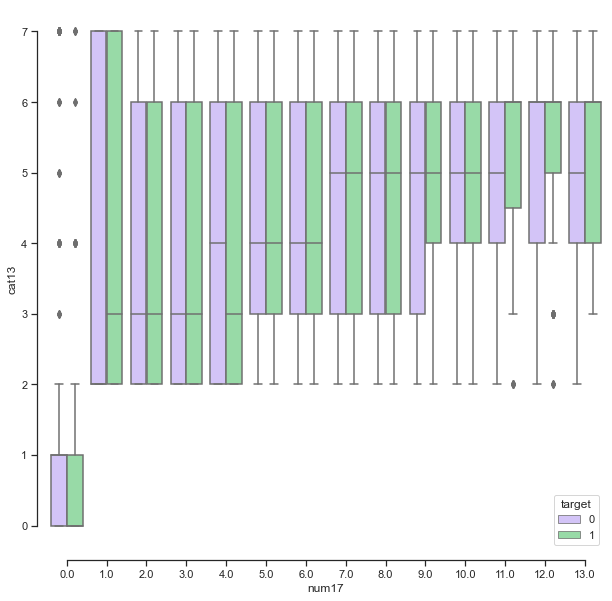

In [65]:
#positively correlated 
#correlation 0.5
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat13,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [2, 10]

plt.show()



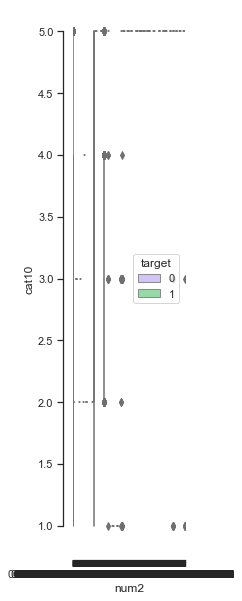

In [69]:
#positively correlated 
#correlation 0.51
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num2, y=df.cat10,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [2, 10]

plt.show()


In [ ]:
#negatively correlated 
#correlation -0.8
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat10,
            hue=df.target, palette=["m", "g"],
            data=df)

plt.show()#negatively correlated 


In [ ]:
#correlation -0.82
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat2,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [1, 10]
plt.show()



In [ ]:
#negatively correlated 
#correlation -0.82
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat2,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [1, 10]
plt.show()




In [ ]:
#almost not correlated 
#correlation -0.0003
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num27, y=df.cat13,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()




In [ ]:
#almost not correlated 
#correlation 0.00082
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num27, y=df.cat14,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()